# LHS 1140 b y c: radios a partir de la fotometria de TESS (PyTransit + MCMC)

**Objetivo:** ajustar los transitos de LHS 1140 b y c con fotometria publica de TESS y obtener sus radios, para combinarlos con las masas que salen de las velocidades radiales de HARPS (Problema 1, Ciencias Planetarias).

**Flujo:** Lightkurve/MAST, limpieza y aplanado (con los transitos enmascarados), conteo de transitos de b y c con datos, BLS, curvas plegadas, PyTransit, MCMC con **emcee**, radio, masa, semieje, diagrama masa-radio con mr-plotter, prueba de excentricidad (efecto fotoexcentrico) y figura del sistema con la zona habitable.

Basado en **02_transit_photometry.ipynb** (WASP-21 b): el radio ya no se estima con el punto minimo de flujo, sino con un modelo fisico, propagando la incertidumbre de $R_\star$.

**Alcance:** se ajustan **b** (P = 24.7 d) y **c** (P = 3.78 d), cada uno por separado con todos sus transitos. Los transitos del otro planeta se enmascaran, tanto en el aplanado como en la ventana de ajuste. No es un ajuste simultaneo ni un analisis de TTV.

Los parametros publicados (Cadieux et al. 2024) son valores iniciales y ventanas de busqueda, no resultados impuestos al ajuste. Requiere internet para descargar TESS desde MAST.

**Resultados principales:** Rp(b) = 1.78 R_earth y Rp(c) = 1.25 R_earth; masas con los K del analisis de RV: Mp(b) = 7.0 +- 0.7 M_earth (+2.0sigma respecto a la literatura, 5.60 +- 0.19) y Mp(c) = 1.96 +- 0.37 M_earth (+0.1sigma). Los semiejes coinciden con la literatura. Con la excentricidad libre, TESS solo da limites al 95 % de 0.45 (b) y 0.44 (c), que no restringen nada frente a los de la literatura (< 0.043 y < 0.050).

**Orden de ejecucion:** corre las celdas de arriba hacia abajo. La descarga de TESS necesita internet. El MCMC corre primero 12000 pasos y la celda de continuacion agrega 13000: todo lo que va despues (resumen, radios, masas, figura final) usa las cadenas alargadas, asi que la continuacion no se puede saltar. Las masas usan los K del notebook de RV y la figura del sistema necesita haber corrido antes radios, masas y semieje.

Orden entre notebooks: descarga de HARPS, LBL, analisis de RV, transitos y zona habitable. Cada uno lee lo que deja el anterior (los espectros, el CSV de velocidades, el K de cada planeta).

## Instalacion e importaciones

Ejecuta una vez en el entorno del notebook.

In [ ]:
%pip install -qU numpy scipy pandas matplotlib astropy lightkurve pytransit emcee corner

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.


### Importamos librerias

In [ ]:
import warnings
from pathlib import Path
from IPython.display import Image

import astropy.units as u
import corner
import emcee
import lightkurve as lk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.timeseries import BoxLeastSquares
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, Patch, Wedge
from pytransit import QuadraticModel

warnings.filterwarnings("ignore")
%matplotlib inline

/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


### Letra grande para las figuras
Funcion que agranda las etiquetas de los ejes, los numeros y las leyendas de una figura para que se lean bien en el articulo.

In [ ]:
def letra_grande(fig, tam_etiqueta=14, tam_numeros=12, tam_leyenda=12):
    # etiquetas, numeros de los ejes y leyendas mas grandes, para el articulo
    for eje in fig.axes:
        eje.xaxis.label.set_size(tam_etiqueta)
        eje.yaxis.label.set_size(tam_etiqueta)
        eje.tick_params(labelsize=tam_numeros)
        leyenda = eje.get_legend()
        if leyenda is not None:
            for texto in leyenda.get_texts():
                texto.set_fontsize(tam_leyenda)

## Configuracion del sistema

LHS 1140 (TIC 92226327, TOI-256) tiene dos planetas transitantes: b (P = 24.7 d) y c (P = 3.78 d). Los tiempos de transito de la Tabla D1 de Cadieux et al. (2024) vienen en BJD - 2 457 000, es decir, ya estan en BTJD. Los parametros sirven como semillas y priors amplios.

**a_rs** se calcula dividiendo el semieje mayor (en ua) entre $R_\star$: el articulo no imprime a/R★. Con $R_\star$ = 0.2159 R_sun, b da unos 94.2 y c unos 26.9.

**fit_names** es la lista de planetas que se ajustan con MCMC (b y c). **planet_names** es la lista para BLS y enmascarado.

### Constantes del sistema

Valores de LHS 1140 tomados de Cadieux et al. (2024). Es el mismo bloque en los notebooks de RV, transitos y zona habitable.

In [ ]:
# constantes de LHS 1140: Cadieux et al. (2024), arXiv:2310.15490. Mismo bloque en los notebooks de RV, transitos y zona habitable
P_ORB = {"b": 24.73723, "c": 3.777940} # d, periodo orbital (Tabla D1)
T0_BTJD = {"b": 1399.9300, "c": 1389.2939} # BJD - 2457000, tiempo de transito (Tabla D1)
M_STAR = 0.1844 # M_sol (Tabla C1)
M_STAR_ERR = 0.0045
R_STAR = 0.2159 # R_sol (Tabla C1)
R_STAR_ERR = 0.0030
TEFF_STAR = 3096.0 # K (Tabla C1)
P_ROT = 131.0 # d, periodo de rotacion (Tabla C1)

### Parametros del objetivo y catalogo
Nombre del objeto en TESS, radio y masa estelares (del bloque de constantes) y catalogo de los dos planetas con los valores de partida del ajuste.

In [ ]:
TARGET = "TIC 92226327" # LHS 1140 (TOI-256) en TESS
BTJD_OFFSET = 2457000.0 # BTJD = BJD - 2457000 (definicion)

# cadieux et al. (2024), Tabla C1
RSTAR_RSUN, RSTAR_ERR_RSUN = R_STAR, R_STAR_ERR # del bloque de constantes
MSTAR_MSUN, MSTAR_ERR_MSUN = M_STAR, M_STAR_ERR

# cadieux et al. (2024): P y T0 de la Tabla D1 (T0 en BJD-2457000 = BTJD),
# b (parametro de impacto) de la Tabla D1, Rp/R* de la Tabla 1, radios del resumen del articulo. a_rs calculado (ver arriba).
# mask_dur = ancho (d) de la mascara de transito para el aplanado (~1.7 x T14), valor elegido en este trabajo.
catalog = {
    "b": {"period": P_ORB["b"], "t0_btjd": T0_BTJD["b"],
          "a_rs": 94.2, "b_impact": 0.23, "k": 0.0733,
          "rp_rearth_literature": 1.730, "mask_dur": 0.15},
    "c": {"period": P_ORB["c"], "t0_btjd": T0_BTJD["c"],
          "a_rs": 26.9, "b_impact": 0.09, "k": 0.0539,
          "rp_rearth_literature": 1.272, "mask_dur": 0.10}
}

planet_names = list(catalog.keys()) # para BLS y enmascarado
fit_names = ["b", "c"] # planetas que se ajustan con MCMC

pd.DataFrame(catalog).T[[
    "period", "t0_btjd", "a_rs", "b_impact", "k",
    "rp_rearth_literature"
]]

,period,t0_btjd,a_rs,b_impact,k,rp_rearth_literature
b,24.73723,1399.9300,94.2,0.23,0.0733,1.730
c,3.77794,1389.2939,26.9,0.09,0.0539,1.272


## Descargar curvas de luz de TESS

Se intenta primero recuperar productos SPOC de 120 segundos. Si no hay productos con esa cadencia, se buscan otras cadencias SPOC. No se selecciona un indice fijo del resultado: se inspeccionan y descargan los productos encontrados.

In [ ]:
search_result = lk.search_lightcurve(
    TARGET, mission="TESS", author="SPOC", exptime=120
)

if len(search_result) == 0:
    print("No hay productos SPOC de 120 s; buscando otras cadencias.")
    search_result = lk.search_lightcurve(
        TARGET, mission="TESS", author="SPOC"
    )

if len(search_result) == 0:
    raise RuntimeError("MAST no devolvio curvas SPOC para LHS 1140.")

display(search_result.table)

intentType,obs_collection,provenance_name,instrument_name,project,filters,wave_region,target_name,target_classification,obs_id,s_ra,s_dec,dataproduct_type,proposal_pi,calib_level,t_min,t_max,t_exptime,wavelength_region,em_min,em_max,obs_title,t_obs_release,proposal_id,proposal_type,sequence_number,s_region,jpegURL,dataURL,dataRights,mtFlag,srcDen,obsid,objID,wave_min,wave_max,exptime,distance,obsID,obs_collection_products,dataproduct_type_products,description,type,dataURI,productType,productGroupDescription,productSubGroupDescription,productDocumentationURL,project_products,prvversion,proposal_id_products,productFilename,size,parent_obsid,dataRights_products,calib_level_products,filters_products,author,mission,#,year,sort_order
,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,s,arcsec,,,,,,,,,,,,,,,,,,,,,,,,
str7,str4,str4,str10,str4,str4,str7,str8,str1,str52,float64,float64,str10,str14,int64,float64,float64,float64,str7,float64,float64,str1,float64,str41,str1,int64,str47,str1,str79,str6,bool,float64,str9,str10,float64,float64,float64,float64,str9,str4,str10,str33,str1,str81,str7,str28,str7,str1,str4,str35,str41,str63,int64,str9,str6,int64,str4,str4,object,object,int64,int64
science,TESS,SPOC,Photometer,TESS,TESS,Optical,92226327,--,tess2018263035959-s0003-0000000092226327-0123-s,11.2472145795075,-15.2715397578344,timeseries,"Ricker, George",3,58381.53855399306,58408.88820246528,120.0,Optical,600.0,1000.0,--,58507.6666666,G011112_G011216_G011183_G011231_G011180,--,3,CIRCLE 11.24721458 -15.27153976 0.00138889,--,mast:TESS/product/tess2018263035959-s0003-0000000092226327-0123-s_lc.fits,PUBLIC,False,nan,60914789,112884716,600.0,1000.0,120,0.0,60914789,TESS,timeseries,Light curves,S,mast:TESS/product/tess2018263035959-s0003-0000000092226327-0123-s_lc.fits,SCIENCE,Minimum Recommended Products,LC,--,SPOC,5c21567b49,G011112_G011216_G011183_G011231_G011180,tess2018263035959-s0003-0000000092226327-0123-s_lc.fits,1998720,60914789,PUBLIC,3,TESS,SPOC,TESS Sector 03,None,2018,1
science,TESS,SPOC,Photometer,TESS,TESS,Optical,92226327,--,tess2020266004630-s0030-0000000092226327-0195-s,11.2472145795075,-15.2715397578344,timeseries,"Ricker, George",3,59115.38962216,59142.01275661,120.0,Optical,600.0,1000.0,--,59173.0,G03250_G03278_G03228_G03106_G03274_G03052,--,30,CIRCLE ICRS 11.24721458 -15.27153976 0.00138889,--,mast:TESS/product/tess2020266004630-s0030-0000000092226327-0195-s_lc.fits,PUBLIC,False,nan,27976504,71530558,600.0,1000.0,120,0.0,27976504,TESS,timeseries,Light curves,S,mast:TESS/product/tess2020266004630-s0030-0000000092226327-0195-s_lc.fits,SCIENCE,Minimum Recommended Products,LC,--,SPOC,6373c68b73,G03250_G03278_G03228_G03106_G03274_G03052,tess2020266004630-s0030-0000000092226327-0195-s_lc.fits,1998720,27976504,PUBLIC,3,TESS,SPOC,TESS Sector 30,None,2020,1
science,TESS,SPOC,Photometer,TESS,TESS,OPTICAL,92226327,--,tess2026221103959-s0107-0000000092226327-0309-s,11.2472145795075,-15.2715397578344,timeseries,"Ricker, George",3,61261.60451888889,61290.27816753472,120.0,OPTICAL,600.0,1000.0,--,61314.0,G08140,--,107,CIRCLE 11.24721458 -15.27153976 0.00138889,--,mast:TESS/product/tess2026221103959-s0107-0000000092226327-0309-s_lc.fits,PUBLIC,False,nan,453944166,1216720428,600.0,1000.0,120,0.0,453944166,TESS,timeseries,Light curves,S,mast:TESS/product/tess2026221103959-s0107-0000000092226327-0309-s_lc.fits,SCIENCE,Minimum Recommended Products,LC,--,SPOC,8c3f9e890a,G08140,tess2026221103959-s0107-0000000092226327-0309-s_lc.fits,2096640,453944166,PUBLIC,3,TESS,SPOC,TESS Sector 107,None,2026,1


### Descargar los productos

In [ ]:
lc_collection = search_result.download_all()

if lc_collection is None or len(lc_collection) == 0:
    raise RuntimeError("No se pudieron descargar curvas de luz.")

print(f"Productos descargados: {len(lc_collection)}")
lc_collection

Productos descargados: 3


LightCurveCollection of 3 objects:
    0: <TessLightCurve LABEL="TIC 92226327" SECTOR=3 AUTHOR=SPOC FLUX_ORIGIN=pdcsap_flux>
    1: <TessLightCurve LABEL="TIC 92226327" SECTOR=30 AUTHOR=SPOC FLUX_ORIGIN=pdcsap_flux>
    2: <TessLightCurve LABEL="TIC 92226327" SECTOR=107 AUTHOR=SPOC FLUX_ORIGIN=pdcsap_flux>

### Guardar copias FITS originales

In [ ]:
PROJECT_DIR = Path.cwd()
RAW_DIR = PROJECT_DIR / "data" / "raw" / TARGET
PROCESSED_DIR = PROJECT_DIR / "data" / "processed" / TARGET
RESULTS_DIR = PROJECT_DIR / "data" / "results" / TARGET

for folder in (RAW_DIR, PROCESSED_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

for j, one_lc in enumerate(lc_collection):
    sector = one_lc.meta.get("SECTOR", j)
    out = RAW_DIR / f"{TARGET}_sector_{sector}.fits"
    one_lc.to_fits(str(out), overwrite=True)
    print("Guardado:", out)

Guardado: /content/data/raw/TIC 92226327/TIC 92226327_sector_3.fits
Guardado: /content/data/raw/TIC 92226327/TIC 92226327_sector_30.fits
Guardado: /content/data/raw/TIC 92226327/TIC 92226327_sector_107.fits


## Inspeccion y preprocesamiento

Se conserva el metodo del notebook original: **stitch**, **flatten** y eliminacion de outliers. Se utiliza un umbral conservador para reducir el riesgo de eliminar puntos reales del transito. El aplanado puede modificar la profundidad o duracion si la ventana del filtro es demasiado corta; se debe comprobar la sensibilidad de los resultados a esta eleccion.

Aqui el aplanado se hace con los transitos de b y c enmascarados (**mask=**), para que el filtro no los trate como tendencia.

Numero de puntos: 42973
Intervalo BTJD: 1385.941465292972 a 4290.776885014625


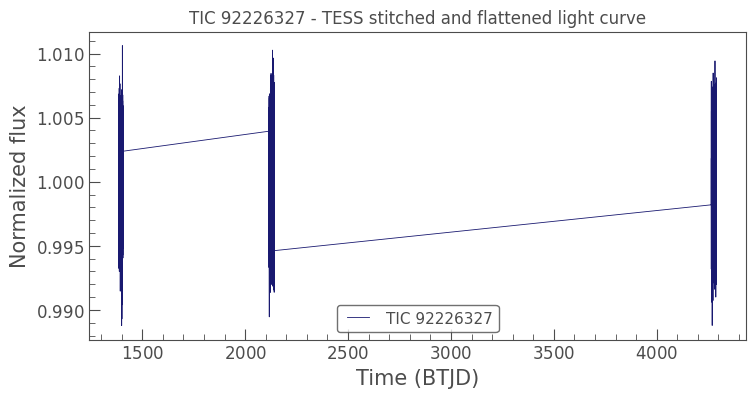

In [ ]:
lc_stitched = lc_collection.stitch().remove_nans()

# enmascarar los transitos conocidos (b y c) para que el aplanado no recorte su profundidad
mask_transitos = lc_stitched.create_transit_mask(
    period=[catalog[p]["period"] for p in planet_names],
    transit_time=[catalog[p]["t0_btjd"] for p in planet_names],
    duration=[catalog[p]["mask_dur"] for p in planet_names]
)

# ventana del filtro (901 puntos), tolerancia de huecos y corte de outliers (8 sigma): valores elegidos en este trabajo
lc = lc_stitched.flatten(window_length=901, break_tolerance=5, mask=mask_transitos)
lc = lc.remove_outliers(sigma_lower=8, sigma_upper=8)
lc = lc.remove_nans()

print("Numero de puntos:", len(lc))
print("Intervalo BTJD:", float(np.nanmin(lc.time.value)),
      "a", float(np.nanmax(lc.time.value)))

ax = lc.plot(color="midnightblue", linewidth=0.6)
ax.set_title(f"{TARGET} - TESS stitched and flattened light curve")
ax.set_xlabel("Time (BTJD)")
ax.set_ylabel("Normalized flux")
plt.show()

### Extraer arrays y revisar la cadencia

In [ ]:
time = np.asarray(lc.time.value, dtype=float)
flux = np.asarray(lc.flux.value, dtype=float)
flux_err = np.asarray(lc.flux_err.value, dtype=float)

valid = (np.isfinite(time) & np.isfinite(flux) &
         np.isfinite(flux_err) & (flux_err > 0))
time, flux, flux_err = time[valid], flux[valid], flux_err[valid]

order = np.argsort(time)
time, flux, flux_err = time[order], flux[order], flux_err[order]

exptime_days = float(lc.meta.get("TIMEDEL", 2 / 1440)) # cadencia en dias (2 minutos si no esta en el header)

# cadencia corta: 1 muestra. Cadencia larga: supersampling (0.005 d y 15 muestras, valores elegidos en este trabajo)
nsamples = 1 if exptime_days < 0.005 else 15

print(f"Exposure time: {exptime_days:.6f} d")
print(f"Supersampling: {nsamples}")
print(f"Median photometric uncertainty: {np.nanmedian(flux_err):.3e}")

Exposure time: 0.001389 d
Supersampling: 1
Median photometric uncertainty: 2.285e-03


## Conteo de transitos de b y c: ¿cuantos tienen datos?

Con P = 24.7 d y sectores de unos 27 d, b tendra como mucho 1 o 2 transitos por sector, y algunos pueden caer en el hueco entre orbitas. c (P = 3.78 d) tendra bastantes mas. Hay que contarlos antes de ajustar.

Se cuentan los puntos a +-0.05 d de cada transito esperado (caben 72 de 120 s). Un transito se considera **completo** si tiene al menos 65 puntos (unos 90 %) y **parcial** si tiene menos.

In [ ]:
# conteo de transitos, elaborado con ayuda de Claude Sonnet 5.5 (Anthropic)
UMBRAL_COMPLETO = 65 # ~90 % de los 72 puntos de 120 s que caben en +-0.05 d
t_ini = np.nanmin(time)
t_fin = np.nanmax(time)

for planeta in fit_names:
    P = catalog[planeta]["period"]
    T0 = catalog[planeta]["t0_btjd"]

    n_min = int(np.floor((t_ini - T0) / P))
    n_max = int(np.ceil((t_fin - T0) / P))

    tn_con_datos = []
    puntos = []
    for n in range(n_min, n_max + 1):
        tn = T0 + n * P
        cuenta = np.sum(np.abs(time - tn) < 0.05)
        if cuenta > 0:
            tn_con_datos.append(tn)
            puntos.append(int(cuenta))

    print(planeta, ":", len(tn_con_datos), "transitos con datos")
    print("puntos por transito:", puntos)
    if len(puntos) > 0:
        print("promedio de puntos:", np.mean(puntos))
        n_comp = sum(p >= UMBRAL_COMPLETO for p in puntos)
        print(f"completos (>= {UMBRAL_COMPLETO} puntos): {n_comp} | parciales: {len(puntos) - n_comp}")

b : 3 transitos con datos
puntos por transito: [71, 72, 72]
promedio de puntos: 71.66666666666667
completos (>= 65 puntos): 3 | parciales: 0
c : 17 transitos con datos
puntos por transito: [72, 72, 72, 66, 72, 72, 72, 72, 72, 72, 72, 72, 72, 64, 53, 31, 11]
promedio de puntos: 64.05882352941177
completos (>= 65 puntos): 13 | parciales: 4


## Busqueda BLS de b y c

Se calcula un periodograma BLS por planeta dentro de una ventana de 0.5 % alrededor de su periodo de referencia. Esto refina señales conocidas; no es una busqueda ciega de planetas desconocidos.

In [ ]:
bls_results = {}
periodograms = {}

# trabajamos con arrays NumPy sin unidades
# tiempo en BTJD (dias), flujo normalizado.

bls_model = BoxLeastSquares(
    time,
    flux,
    dy=flux_err
)

# duraciones de transito en dias, rango elegido en este trabajo
durations_days = np.linspace(0.035, 0.18, 30)

Para cada planeta se corre el BLS en una ventana de +-0.5 % alrededor de su periodo de referencia y se guarda el mejor periodo, el T0 y la profundidad

In [ ]:
for planet in planet_names:
    p_ref = catalog[planet]["period"]

    periods_days = np.linspace(
        p_ref * 0.995,
        p_ref * 1.005,
        2500
    )

    result = bls_model.power(
        periods_days,
        durations_days,
        objective="likelihood"
    )

    best_index = int(np.argmax(result.power))

    periodograms[planet] = {
        "period": np.asarray(result.period),
        "power": np.asarray(result.power)
    }

    bls_results[planet] = {
        "period": float(result.period[best_index]),
        "t0": float(result.transit_time[best_index]),
        "duration": float(result.duration[best_index]),
        "depth": float(result.depth[best_index])
    }

    r = bls_results[planet]

    periodo_bls = r["period"]
    duracion_h = r["duration"] * 24
    profundidad_ppt = r["depth"] * 1e3
    print(f"LHS 1140 {planet}: P={periodo_bls:.8f} d, duration={duracion_h:.2f} h, depth={profundidad_ppt:.3f} ppt")

LHS 1140 b: P=24.73727949 d, duration=1.93 h, depth=5.628 ppt
LHS 1140 c: P=3.77793244 d, duration=1.09 h, depth=2.810 ppt


### Periodogramas BLS

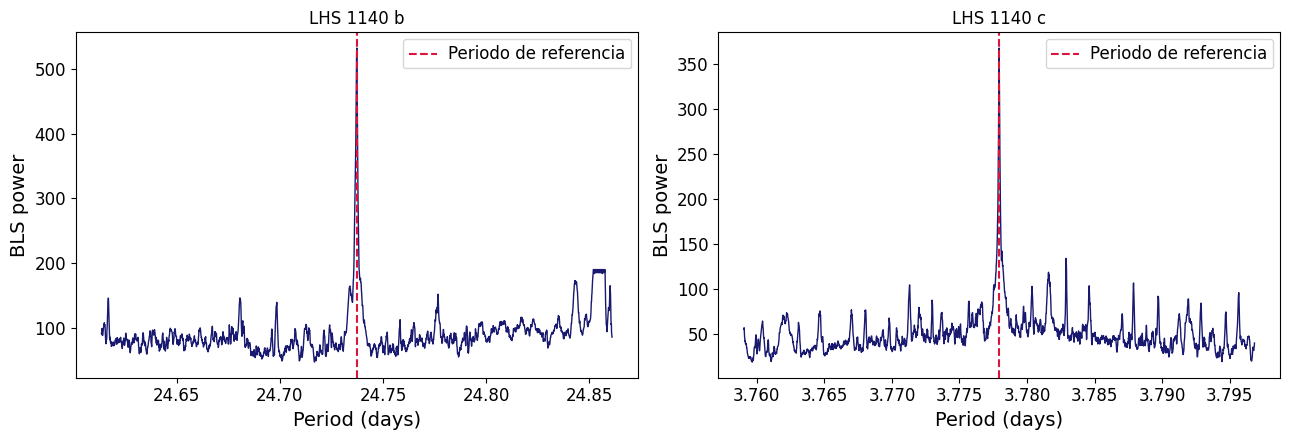

In [ ]:
# Claude Sonnet 5.5 (Anthropic): codigo de la figura
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, planet in zip(axes.flat, planet_names):

    pg = periodograms[planet]

    ax.plot(
        pg["period"],
        pg["power"],
        color="midnightblue",
        lw=1
    )

    ax.axvline(
        catalog[planet]["period"],
        color="crimson",
        ls="--",
        label="Periodo de referencia"
    )

    ax.set_title(f"LHS 1140 {planet}")
    ax.set_xlabel("Period (days)")
    ax.set_ylabel("BLS power")
    ax.legend()

letra_grande(fig)
plt.tight_layout()
plt.show()

## Curvas plegadas

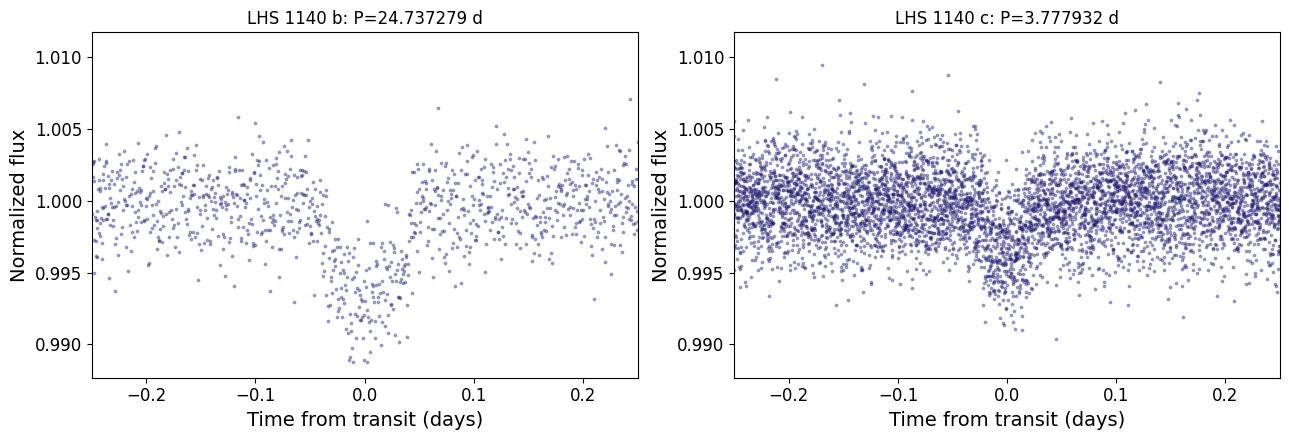

In [ ]:
# Claude Sonnet 5.5 (Anthropic): codigo de la figura
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, planet in zip(axes.flat, planet_names):
    p = bls_results[planet]["period"]
    t0 = bls_results[planet]["t0"]
    folded = lc.fold(period=p * u.day, epoch_time=t0 * u.day)

    ax.scatter(folded.phase.to_value(u.day), folded.flux.value,
               s=3, alpha=0.35, color="midnightblue")
    ax.set_xlim(-0.25, 0.25)
    ax.set_title(f"LHS 1140 {planet}: P={p:.6f} d")
    ax.set_xlabel("Time from transit (days)")
    ax.set_ylabel("Normalized flux")

letra_grande(fig)
plt.tight_layout()
plt.show()

## Modelo fisico con PyTransit

Se utiliza **QuadraticModel**, que implementa el modelo analitico de transito con oscurecimiento al limbo cuadratico:

$$
I(\mu)=1-u_1(1-\mu)-u_2(1-\mu)^2.
$$

Para una orbita circular:

$$
  b = \frac{a}{R_{star}} \cos i
$$

$$
i = \arccos\left( \frac{b}{a/R_{star}} \right).
$$

Los coeficientes de limb darkening vienen de la solucion de TESS de Cadieux et al. (2024, Tabla D2): q1 = 0.33 y q2 = 0.56, convertidos a u1 = 0.643 y u2 = -0.069 (Kipping 2013). Se fijan; una mejora seria ajustarlos con priors.

In [ ]:
# cadieux et al. (2024), Tabla D2, TESS: q1 = 0.33, q2 = 0.56 (Kipping 2013)
# u1 = 2*sqrt(q1)*q2 = 0.643 ; u2 = sqrt(q1)*(1 - 2*q2) = -0.069
LD_COEFF = np.array([0.643, -0.069])

def make_transit_model(t):
    model = QuadraticModel()
    model.set_data(
        np.asarray(t, dtype=float),
        exptimes=exptime_days,
        nsamples=nsamples
    )
    return model


def evaluate_planet_transit(model, theta):
    # theta = [k, t0, period, a/Rstar, impact, log_jitter]
    k, t0, period, a_rs, impact, log_jitter = theta
    cos_i = np.clip(impact / a_rs, -1.0, 1.0)
    inclination = np.arccos(cos_i)

    return model.evaluate(
        k=k, ldc=LD_COEFF, t0=t0, p=period,
        a=a_rs, i=inclination
    )

## Seleccionar ventanas de transito

Para ajustar cada planeta se usan las observaciones proximas a todos sus transitos. Se excluyen ademas las ventanas donde se esperan transitos de los otros planetas, para que sus señales no contaminen el ajuste individual.

In [ ]:
def wrapped_time_distance(t, period, t0):
    return (t - t0 + 0.5 * period) % period - 0.5 * period


def epoch_near_data(t0, period, time_array):
    t_mid = np.nanmedian(time_array)
    n = np.round((t_mid - t0) / period)
    return t0 + n * period


# ventanas en dias (alrededor del propio transito y alrededor de los del otro planeta), valores elegidos en este trabajo
def select_planet_data(planet, half_window=0.18, other_planet_mask=0.12):
    p0 = bls_results[planet]["period"]
    t0_bls = bls_results[planet]["t0"]
    t0_ref = epoch_near_data(t0_bls, p0, time)

    own_distance = np.abs(wrapped_time_distance(time, p0, t0_ref))
    mask = own_distance < half_window

    for other in planet_names:
        if other == planet:
            continue
        p_other = bls_results[other]["period"]
        t0_other = epoch_near_data(bls_results[other]["t0"], p_other, time)
        other_distance = np.abs(
            wrapped_time_distance(time, p_other, t0_other)
        )
        mask &= other_distance > other_planet_mask

    return time[mask], flux[mask], flux_err[mask], t0_ref


for planet in planet_names:
    tp, fp, ep, t0ref = select_planet_data(planet)
    print(f"Planet {planet}: {len(tp)} points; reference epoch BTJD={t0ref:.6f}")

Planet b: 776 points; reference epoch BTJD=2142.044100
Planet c: 3997 points; reference epoch BTJD=2133.548906


## Inferencia bayesiana

Para cada planeta se estiman seis parametros:

- $k=R_p/R_\star$: radio relativo.
- $T_0$: epoca de transito de referencia (BTJD).
- $P$: periodo orbital (dias).
- $a/R_\star$: semieje mayor relativo.
- $b$: parametro de impacto.
- $\ln\sigma_{\rm jit}$: logaritmo del ruido adicional.

Se usa:

$$
p(\theta\mid D)\propto\mathcal{L}(D\mid\theta)p(\theta),
\qquad
\sigma_i^2=\sigma_{\mathrm{phot},i}^2+\sigma_{\mathrm{jit}}^2.
$$

Los priors son uniformes dentro de limites fisicos y ventanas alrededor de los valores de referencia.

In [ ]:
def log_prior(theta, planet, t0_ref, p_ref):
    k, t0, period, a_rs, impact, log_jitter = theta
    a0 = catalog[planet]["a_rs"]
    # limites de los priors uniformes, elegidos en este trabajo

    if not (0.003 < k < 0.12):
        return -np.inf
    if not (abs(t0 - t0_ref) < 0.10):
        return -np.inf
    if not (abs(period - p_ref) < 0.005 * p_ref):
        return -np.inf
    if not (0.5 * a0 < a_rs < 1.5 * a0):
        return -np.inf
    if not (0.0 <= impact < 1.0 + k):
        return -np.inf

    jitter = np.exp(log_jitter)
    if not (1e-7 < jitter < 0.02):
        return -np.inf

    return 0.0

### Log-probabilidad
Prior uniforme y verosimilitud gaussiana con ruido extra (jitter). Si el modelo no es finito, el punto se descarta

In [ ]:
def log_probability(theta, planet, t, f, ferr, model, t0_ref, p_ref):
    lp = log_prior(theta, planet, t0_ref, p_ref)
    if not np.isfinite(lp):
        return -np.inf

    model_flux = evaluate_planet_transit(model, theta)
    if not np.all(np.isfinite(model_flux)):
        return -np.inf

    jitter = np.exp(theta[-1])
    variance = ferr**2 + jitter**2
    residuals = f - model_flux

    loglike = -0.5 * np.sum(
        residuals**2 / variance + np.log(2.0 * np.pi * variance)
    )
    return loglike + lp

## Ejecutar MCMC

Se utiliza **emcee** con 32 caminantes inicializados cerca de los valores BLS y de referencia. La primera corrida es de 12000 pasos; como no alcanzo 50 veces el tiempo de autocorrelacion, se continua en la seccion Diagnosticos MCMC y continuacion de las cadenas.

In [ ]:
NWALKERS = 32
NSTEPS = 12000
BURNIN = 2000
THIN = 50 # valores elegidos en este trabajo

# nombres de los parametros del ajuste (se usan en los diagnosticos y en el resumen)
PARAMETER_NAMES = [
    "k = Rp/Rstar", "T0 (BTJD)", "Period (days)",
    "a/Rstar", "Impact parameter", "ln(jitter)"
]

### Posiciones iniciales
Los caminantes arrancan cerca de los valores del BLS y del catalogo. Si alguno cae fuera del prior, se vuelve a sortear.

In [ ]:
def posiciones_iniciales(planet, t0_ref, p_ref, random_seed):
    k0 = catalog[planet]["k"]
    a0 = catalog[planet]["a_rs"]
    b0 = catalog[planet]["b_impact"]

    center = np.array([k0, t0_ref, p_ref, a0, b0, np.log(3e-4)])
    # dispersion inicial de cada parametro, valores elegidos en este trabajo
    scales = np.array([
        max(k0 * 0.04, 2e-4),
        0.002,
        p_ref * 2e-5,
        max(a0 * 0.01, 0.05),
        0.015,
        0.25
    ])

    rng = np.random.default_rng(random_seed)
    pos = center + scales * rng.normal(size=(NWALKERS, len(center)))

    for j in range(NWALKERS):
        attempts = 0
        while not np.isfinite(log_prior(pos[j], planet, t0_ref, p_ref)):
            pos[j] = center + scales * rng.normal(size=len(center))
            attempts += 1
            if attempts > 10000:
                raise RuntimeError("No fue posible inicializar los caminantes.")
    return pos

### Funcion del ajuste
Funcion que ajusta un planeta con emcee: selecciona los datos, inicializa los caminantes, corre la cadena y devuelve las muestras.

In [ ]:
def fit_one_planet(planet, random_seed=42):
    t_fit, f_fit, err_fit, t0_ref = select_planet_data(planet)

    if len(t_fit) < 30:
        raise RuntimeError(f"Muy pocos puntos para LHS 1140 {planet}: {len(t_fit)}")

    p_ref = bls_results[planet]["period"]
    tm = make_transit_model(t_fit)
    pos = posiciones_iniciales(planet, t0_ref, p_ref, random_seed)

    sampler = emcee.EnsembleSampler(
        NWALKERS, pos.shape[1], log_probability,
        args=(planet, t_fit, f_fit, err_fit, tm, t0_ref, p_ref)
    )
    sampler.run_mcmc(pos, NSTEPS, progress=True)

    samples = sampler.get_chain(
        discard=BURNIN, thin=THIN, flat=True
    )

    return {
        "planet": planet, "time": t_fit, "flux": f_fit,
        "flux_err": err_fit, "model": tm, "sampler": sampler,
        "samples": samples, "t0_ref": t0_ref, "p_ref": p_ref
    }

### Ejecutar el ajuste para b y c
Esta celda puede tardar. Para una prueba inicial reduce **NSTEPS**; para resultados finales aumenta la longitud de las cadenas y verifica convergencia.

In [ ]:
fits = {}

for j, planet in enumerate(fit_names):
    print(f"LHS 1140 {planet}")
    fits[planet] = fit_one_planet(planet, random_seed=42 + j)

print("Ajustes terminados:", list(fits.keys()))

LHS 1140 b


100%|██████████| 12000/12000 [00:31<00:00, 384.85it/s]


LHS 1140 c


100%|██████████| 12000/12000 [00:49<00:00, 240.67it/s]

Ajustes terminados: ['b', 'c']


## Diagnosticos MCMC y continuacion de las cadenas

La fraccion de aceptacion y las trazas son diagnosticos, no pruebas aisladas de convergencia. Despues se alargan las cadenas y se calcula el tiempo de autocorrelacion. Todo lo que sigue (resumen, corner plots, radios y masas) usa las cadenas ya alargadas.

In [ ]:
for planet in fit_names:
    sampler = fits[planet]["sampler"]
    print(
        f"LHS 1140 {planet}: mean acceptance fraction = "
        f"{np.mean(sampler.acceptance_fraction):.3f}"
    )

LHS 1140 b: mean acceptance fraction = 0.358
LHS 1140 c: mean acceptance fraction = 0.334


### Trazas de las cadenas

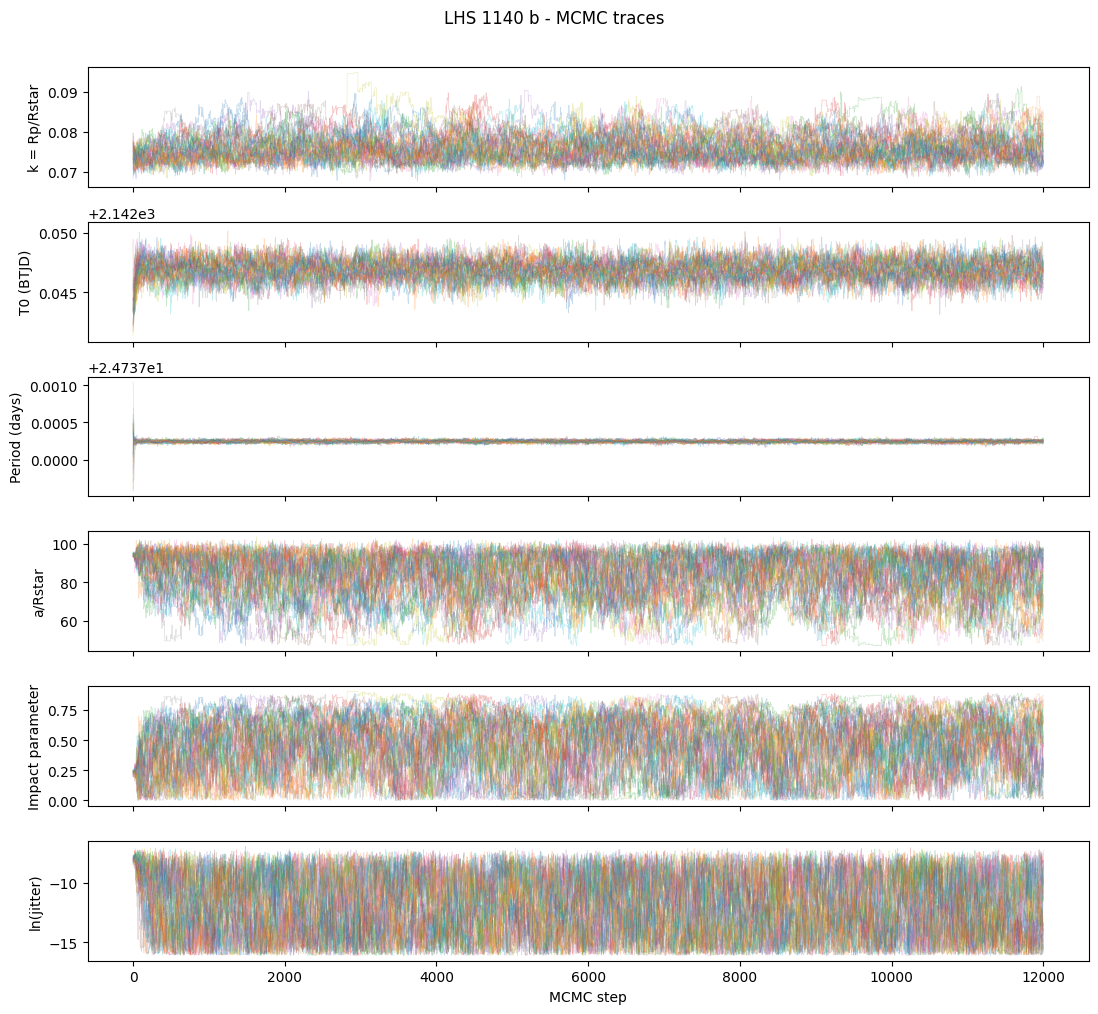

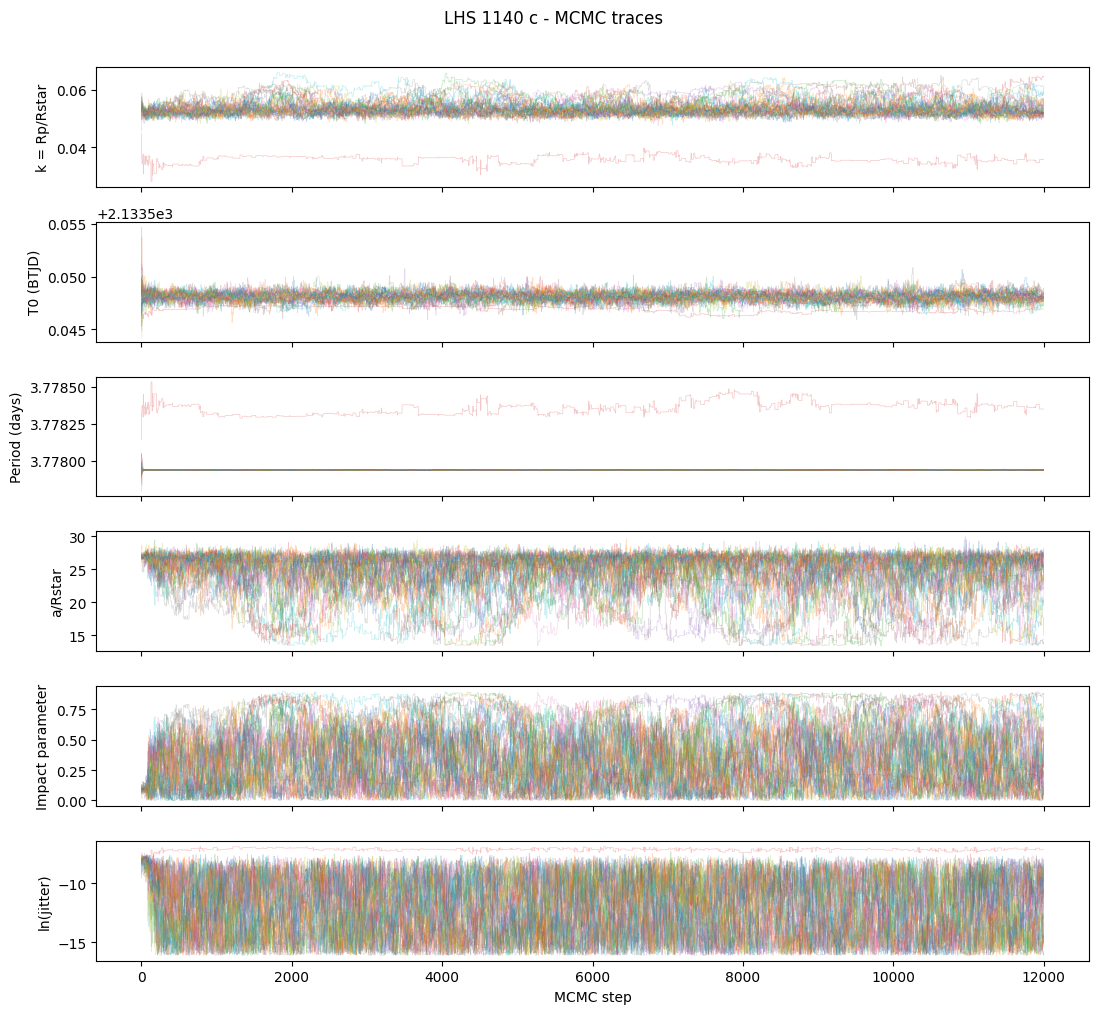

In [ ]:
# Claude Sonnet 5.5 (Anthropic): codigo de la figura
for planet in fit_names:
    chain = fits[planet]["sampler"].get_chain()
    fig, axes = plt.subplots(
        chain.shape[2], 1, figsize=(11, 10), sharex=True
    )
    for i, ax in enumerate(axes):
        ax.plot(chain[:, :, i], alpha=0.25, lw=0.5)
        ax.set_ylabel(PARAMETER_NAMES[i])
    axes[-1].set_xlabel("MCMC step")
    fig.suptitle(f"LHS 1140 {planet} - MCMC traces", y=1.01)
    plt.tight_layout()
    plt.show()

### Continuar las cadenas
La primera corrida no cumplia 50 veces el tiempo de autocorrelacion. Se alargan las cadenas 13000 pasos desde donde quedaron (25000 en total) y se recalculan las muestras, descartando 8000 pasos de burn-in (unas 19 veces el tau de b, 416 pasos, y 11 veces el de c, 711 pasos). Las celdas de resultados que vienen despues usan estas muestras.

Con 25000 pasos, b cumple el criterio de 50 veces tau y c no (ver la celda de tiempos de autocorrelacion). Por eso, justo despues, se alargan las cadenas de c.

In [ ]:
for planet in fit_names:
    fits[planet]["sampler"].run_mcmc(None, 13000, progress=True)
    fits[planet]["samples"] = fits[planet]["sampler"].get_chain(
        discard=8000, thin=100, flat=True
    )

100%|██████████| 13000/13000 [00:54<00:00, 240.38it/s]


### Alargar las cadenas de c
Con 25000 pasos, c no llega a 50 veces el tiempo de autocorrelacion (tau de c = 711 pasos, Steps / max(tau) = 35). Se alargan solo sus cadenas 20000 pasos mas (45000 en total) y se recalculan sus muestras con el mismo burn-in. Despues hay que volver a correr las celdas de tiempos de autocorrelacion y todas las que usan las muestras: resumen, corner plots, radios, masas, semiejes y la figura del sistema.

In [ ]:
PASOS_EXTRA_C = 20000 # pasos extra de c (con tau = 711, 45000 pasos son unas 63 veces tau)
fits["c"]["sampler"].run_mcmc(None, PASOS_EXTRA_C, progress=True)
fits["c"]["samples"] = fits["c"]["sampler"].get_chain(discard=8000, thin=100, flat=True)

100%|██████████| 20000/20000 [01:23<00:00, 240.60it/s]


### Tiempos de autocorrelacion

In [ ]:
for planet in fit_names:
    sampler = fits[planet]["sampler"]
    print(f"\nLHS 1140 {planet}")
    tau = sampler.get_autocorr_time(tol=0)
    for name, value in zip(PARAMETER_NAMES, tau):
        print(f"{name}: tau = {value:.1f}")
    print("Steps / max(tau):", sampler.iteration / np.max(tau))


LHS 1140 b
k = Rp/Rstar: tau = 403.6
T0 (BTJD): tau = 141.7
Period (days): tau = 134.3
a/Rstar: tau = 431.7
Impact parameter: tau = 440.3
ln(jitter): tau = 160.4
Steps / max(tau): 56.77364701049888

LHS 1140 c
k = Rp/Rstar: tau = 659.2
T0 (BTJD): tau = 268.8
Period (days): tau = 175.3
a/Rstar: tau = 773.3
Impact parameter: tau = 686.0
ln(jitter): tau = 171.3
Steps / max(tau): 58.192542218291955


## Resumen de las distribuciones posteriores
Se reportan la mediana y los percentiles 16 y 84; no se presupone que las posteriores sean gaussianas.

In [ ]:
summary_rows = []
for planet in fit_names:
    samples = fits[planet]["samples"]
    row = {"planet": planet}
    for i, name in enumerate(PARAMETER_NAMES):
        p16, p50, p84 = np.percentile(samples[:, i], [16, 50, 84])
        row[name] = p50
        row[name + " lower"] = p50 - p16
        row[name + " upper"] = p84 - p50
    summary_rows.append(row)

posterior_summary = pd.DataFrame(summary_rows).set_index("planet")
display(posterior_summary)

,k = Rp/Rstar,k = Rp/Rstar lower,k = Rp/Rstar upper,T0 (BTJD),T0 (BTJD) lower,T0 (BTJD) upper,Period (days),Period (days) lower,Period (days) upper,a/Rstar,a/Rstar lower,a/Rstar upper,Impact parameter,Impact parameter lower,Impact parameter upper,ln(jitter),ln(jitter) lower,ln(jitter) upper
planet,,,,,,,,,,,,,,,,,,
b,0.075439,0.002783,0.004185,2142.046876,0.000807,0.000782,24.737245,0.000016,0.000016,84.324306,14.946894,10.43770,0.492817,0.319820,0.204934,-12.13200,2.678683,2.807096
c,0.052909,0.001491,0.002887,2133.548056,0.000399,0.000381,3.777936,0.000001,0.000002,25.526299,4.554865,1.45519,0.322892,0.218988,0.313367,-12.06797,2.756023,2.728400


## Corner plots

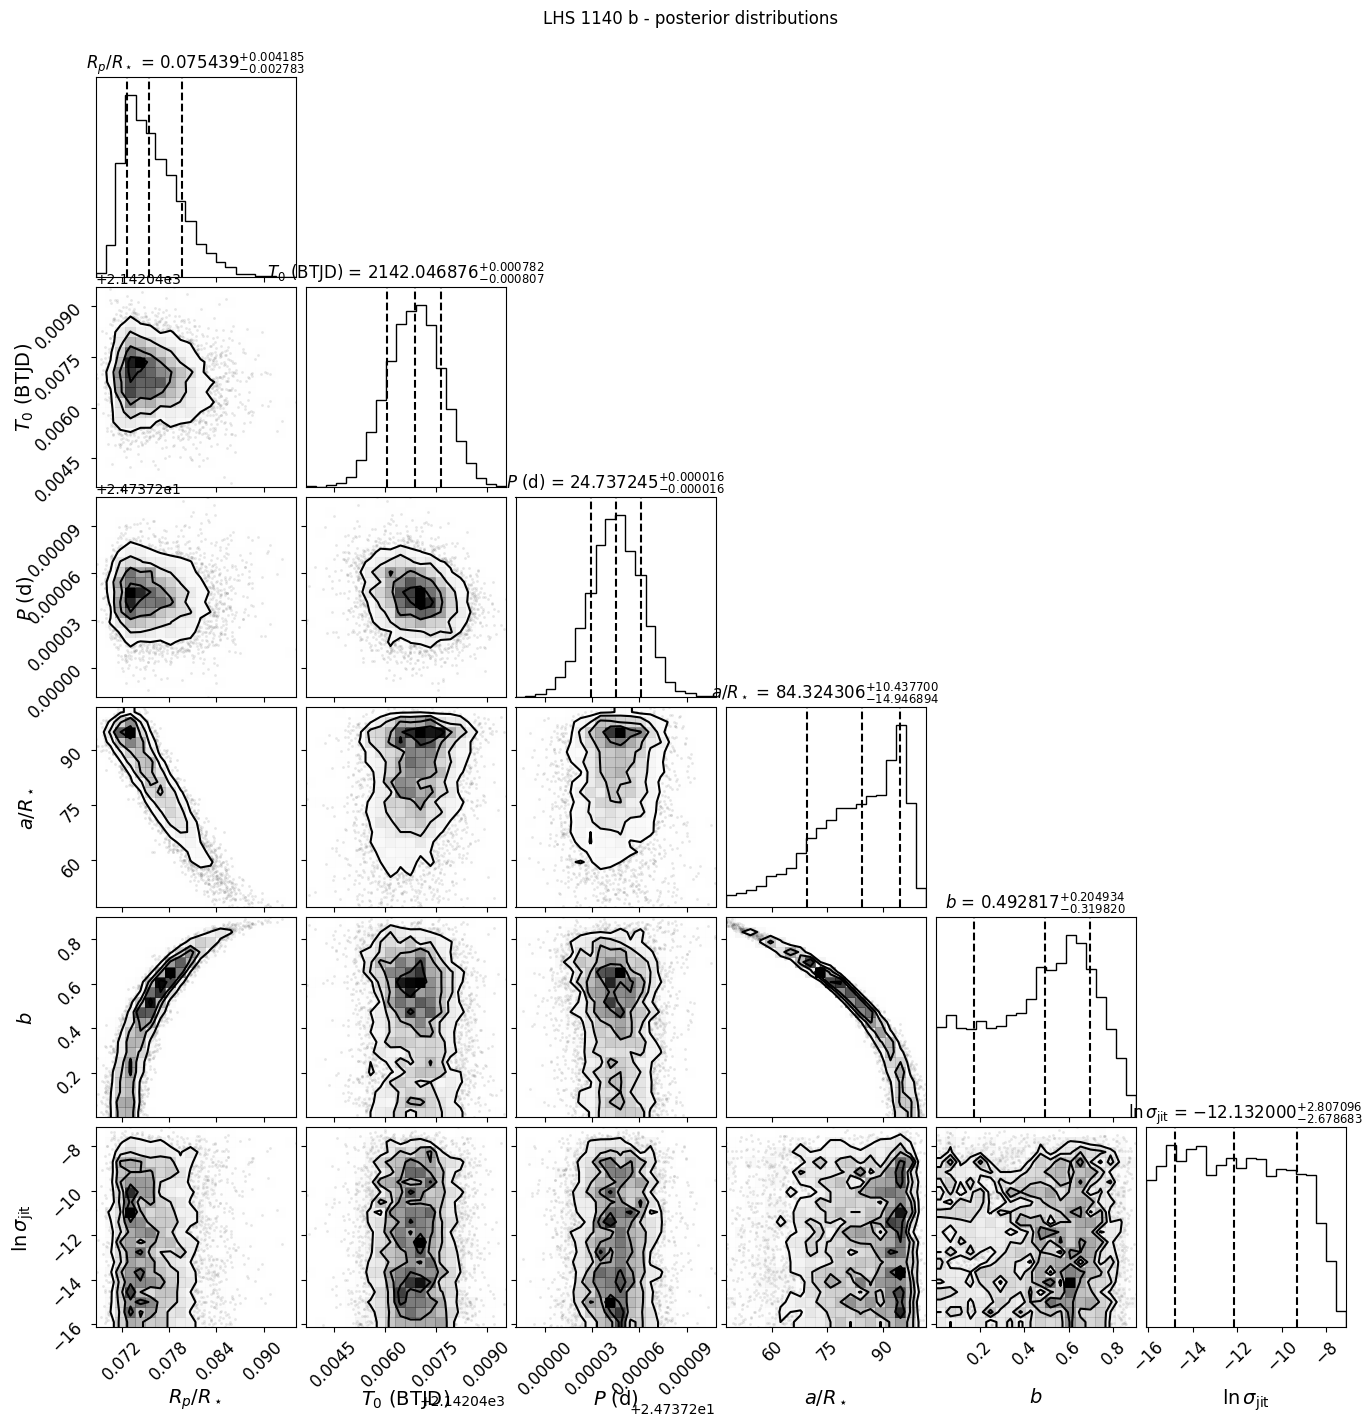

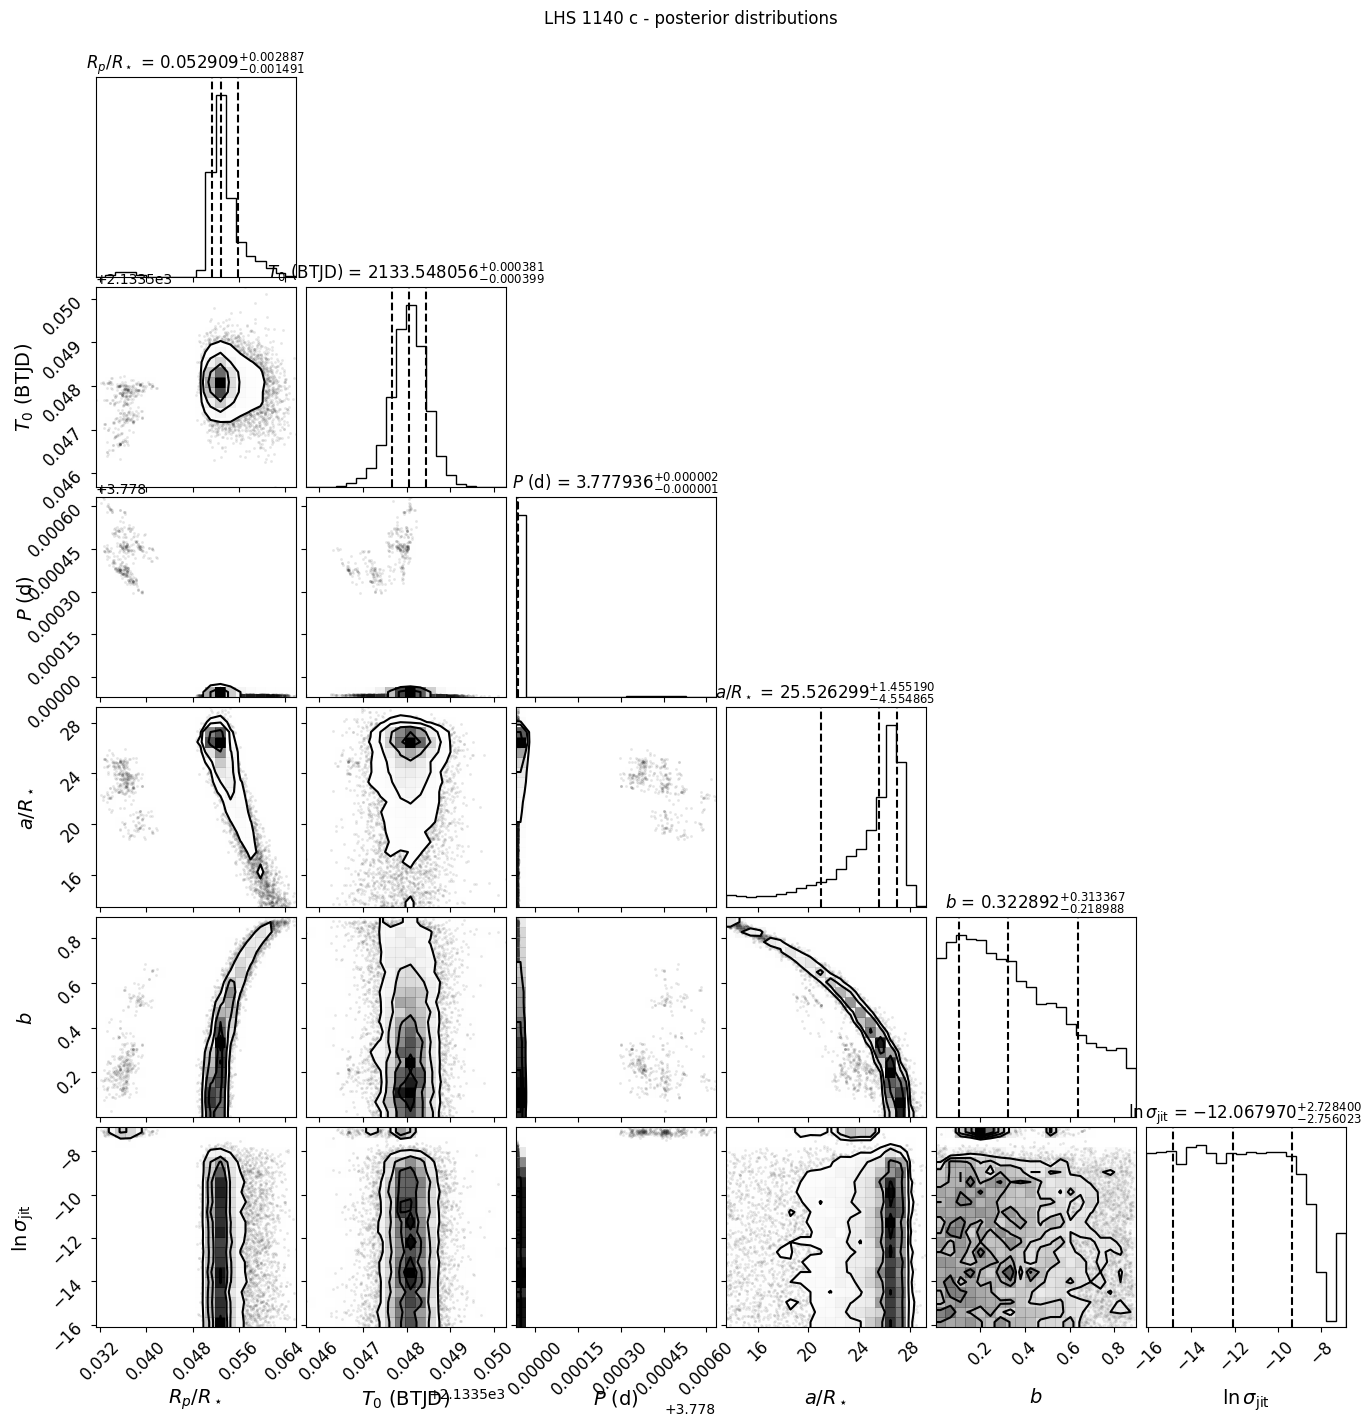

In [ ]:
for planet in fit_names:
    samples = fits[planet]["samples"]
    fig = corner.corner(
        samples,
        labels=[
            r"$R_p/R_\star$", r"$T_0$ (BTJD)", r"$P$ (d)",
            r"$a/R_\star$", r"$b$", r"$\ln\sigma_{\rm jit}$"
        ],
        quantiles=[0.16, 0.50, 0.84],
        show_titles=True,
        title_fmt=".6f"
    )
    fig.suptitle(f"LHS 1140 {planet} - posterior distributions", y=1.02)
    letra_grande(fig)
    plt.show()

## Modelo final y residuos

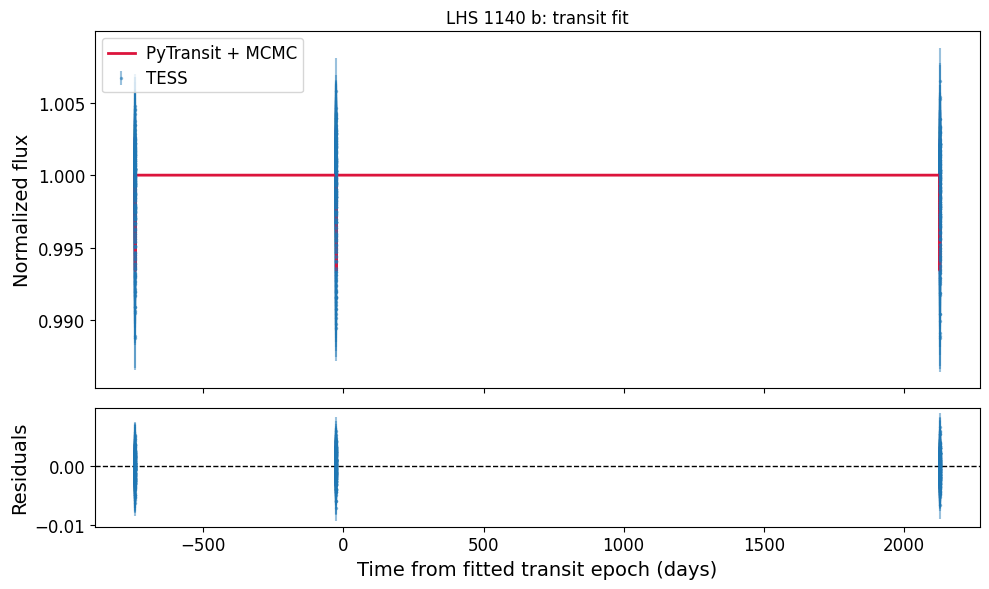

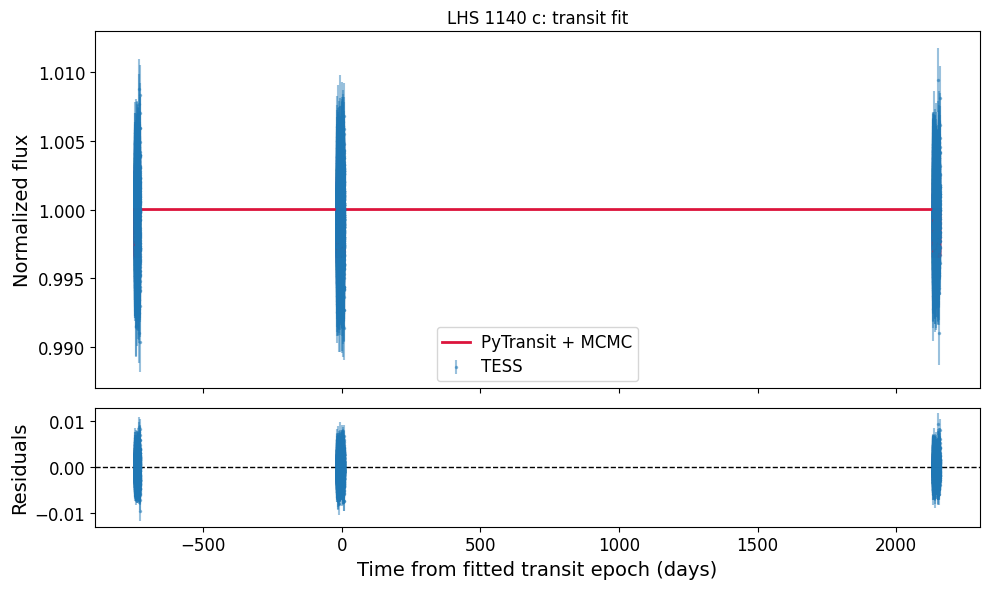

In [ ]:
# Claude Sonnet 5.5 (Anthropic): codigo de la figura
final_models = {}

for planet in fit_names:
    result = fits[planet]
    theta_med = np.median(result["samples"], axis=0)
    model_flux = evaluate_planet_transit(result["model"], theta_med)

    final_models[planet] = {
        "theta_median": theta_med,
        "model_flux": model_flux,
        "residuals": result["flux"] - model_flux
    }

    t_rel = result["time"] - theta_med[1]
    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(10, 6), sharex=True,
        gridspec_kw={"height_ratios": [3, 1]}
    )

    ax1.errorbar(t_rel, result["flux"], yerr=result["flux_err"],
                 fmt=".", ms=3, alpha=0.45, label="TESS")
    ax1.plot(t_rel, model_flux, color="crimson", lw=2,
             label="PyTransit + MCMC")
    ax1.set_ylabel("Normalized flux")
    ax1.set_title(f"LHS 1140 {planet}: transit fit")
    ax1.legend()

    ax2.axhline(0, color="black", ls="--", lw=1)
    ax2.errorbar(t_rel, result["flux"] - model_flux,
                 yerr=result["flux_err"], fmt=".", ms=3, alpha=0.45)
    ax2.set_xlabel("Time from fitted transit epoch (days)")
    ax2.set_ylabel("Residuals")

    letra_grande(fig)
    plt.tight_layout()
    plt.show()

### Curvas plegadas con el modelo (figura del articulo)

Pliega los datos de cada ventana con el $T_0$ y $P$ medianos del MCMC, dibuja la mediana del modelo, su banda 16-84 % (100 muestras del posterior) y los residuos. Guarda **fig_transitos.png**.

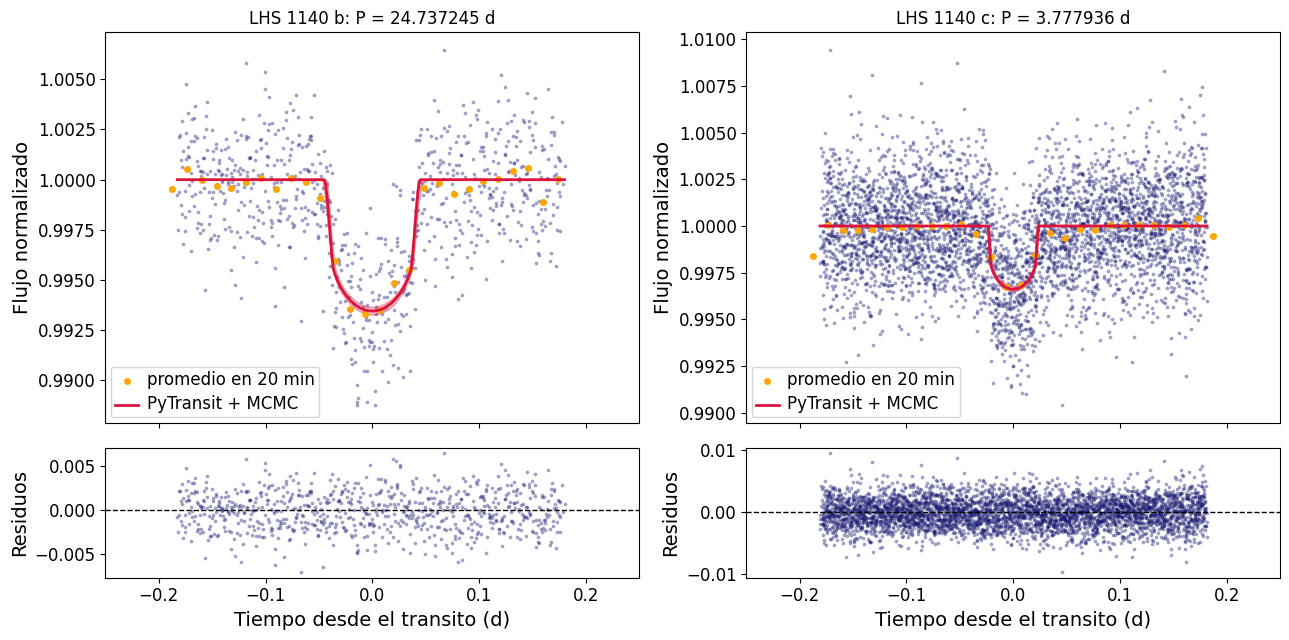

In [ ]:
# Claude Sonnet 5.5 (Anthropic): codigo de la figura
rng = np.random.default_rng(1)
fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1]})
for col, planet in enumerate(fit_names):
    res = fits[planet]
    theta_med = np.median(res["samples"], axis=0)
    T0, P = theta_med[1], theta_med[2]
    t, f, e = res["time"], res["flux"], res["flux_err"]
    fase = ((t - T0 + 0.5 * P) % P) - 0.5 * P
    orden = np.argsort(fase)
    modelo_med = evaluate_planet_transit(res["model"], theta_med)

    # banda 16-84 % con 100 muestras del posterior
    idx = rng.choice(len(res["samples"]), 100, replace=False)
    mods = np.array([evaluate_planet_transit(res["model"], res["samples"][i]) for i in idx])
    lo, hi = np.percentile(mods, [16, 84], axis=0)

    ax1, ax2 = axes[0, col], axes[1, col]
    ax1.scatter(fase, f, s=3, alpha=0.3, color="midnightblue")
    # promedios en bins de 20 min
    bins = np.arange(-0.25, 0.2501, 20 / 1440)
    cen = 0.5 * (bins[1:] + bins[:-1])
    prom = [np.mean(f[(fase >= a) & (fase < b)]) if np.any((fase >= a) & (fase < b)) else np.nan
            for a, b in zip(bins[:-1], bins[1:])]
    ax1.plot(cen, prom, "o", color="orange", ms=4, label="promedio en 20 min")
    ax1.fill_between(fase[orden], lo[orden], hi[orden], color="crimson", alpha=0.3)
    ax1.plot(fase[orden], modelo_med[orden], color="crimson", lw=2, label="PyTransit + MCMC")
    ax1.set_xlim(-0.25, 0.25)
    ax1.set_title(f"LHS 1140 {planet}: P = {P:.6f} d")
    ax1.set_ylabel("Flujo normalizado")
    ax1.legend(fontsize=8)

    ax2.axhline(0, color="k", ls="--", lw=1)
    ax2.scatter(fase, f - modelo_med, s=3, alpha=0.3, color="midnightblue")
    ax2.set_xlabel("Tiempo desde el transito (d)")
    ax2.set_ylabel("Residuos")
letra_grande(fig)
plt.tight_layout()
plt.savefig("fig_transitos.png", dpi=200)
plt.show()

## Convertir $(R_p/R_{star})$ en radio planetario

$$
R_p = (R_p/R_{star})R_{star}.
$$

Se propagan tanto las muestras posteriores de $k$ como la incertidumbre del radio estelar mediante realizaciones Monte Carlo. Se usa $R_\odot/R_\oplus\simeq109.076$.

In [ ]:
RSUN_TO_REARTH = 109.076 # radio solar / radio terrestre, iau 2015
physical_rows = []

for j, planet in enumerate(fit_names):
    samples = fits[planet]["samples"]
    k_samples = samples[:, 0]

    rng = np.random.default_rng(100 + j)
    rstar_draws = rng.normal(
        RSTAR_RSUN, RSTAR_ERR_RSUN, size=len(k_samples)
    )
    rstar_draws = np.clip(rstar_draws, 0.01, None)

    rp_draws = k_samples * rstar_draws * RSUN_TO_REARTH
    p16, p50, p84 = np.percentile(rp_draws, [16, 50, 84])

    physical_rows.append({
        "planet": planet,
        "Rp/Rstar median": np.median(k_samples),
        "Rp median (R_earth)": p50,
        "Rp lower (R_earth)": p50 - p16,
        "Rp upper (R_earth)": p84 - p50,
        "Rp literature (R_earth)": catalog[planet]["rp_rearth_literature"]
    })

physical_results = pd.DataFrame(physical_rows).set_index("planet")
display(physical_results)

,Rp/Rstar median,Rp median (R_earth),Rp lower (R_earth),Rp upper (R_earth),Rp literature (R_earth)
planet,,,,,
b,0.075439,1.778059,0.070275,0.101192,1.730
c,0.052909,1.247429,0.041355,0.069921,1.272


## Comparar con la literatura
La comparacion es un control externo, no un ajuste de los resultados hacia los valores publicados.

,Rp median (R_earth),Rp literature (R_earth),relative difference (%)
planet,,,
b,1.778059,1.730,2.777986
c,1.247429,1.272,-1.931721


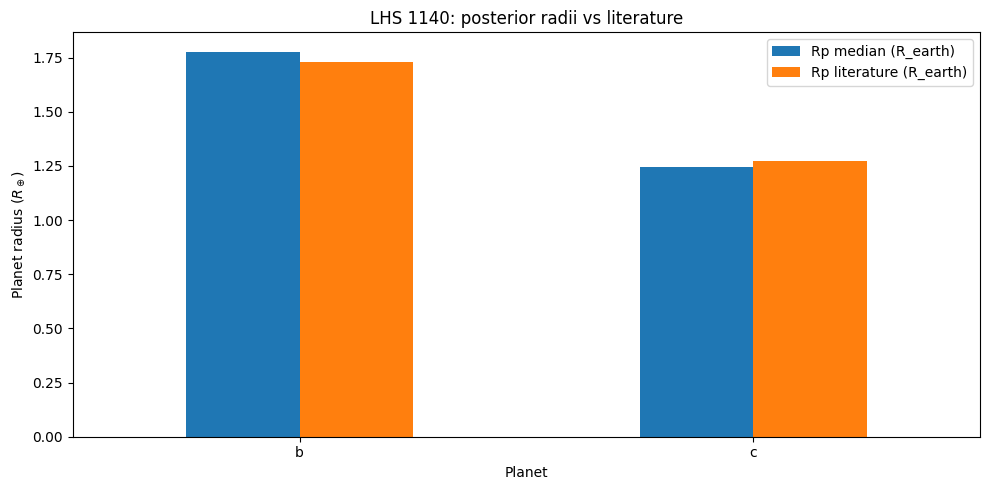

In [ ]:
comparison = physical_results[[
    "Rp median (R_earth)", "Rp literature (R_earth)"
]].copy()

comparison["relative difference (%)"] = (
    100 * (
        comparison["Rp median (R_earth)"] -
        comparison["Rp literature (R_earth)"]
    ) / comparison["Rp literature (R_earth)"]
)

display(comparison)

ax = comparison[[
    "Rp median (R_earth)", "Rp literature (R_earth)"
]].plot(kind="bar", figsize=(10, 5))
ax.set_ylabel(r"Planet radius ($R_\oplus$)")
ax.set_xlabel("Planet")
ax.set_title("LHS 1140: posterior radii vs literature")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Guardar resultados

In [ ]:
summary_file = RESULTS_DIR / "posterior_summary.csv"
physical_file = RESULTS_DIR / "planetary_radii.csv"

posterior_summary.to_csv(summary_file)
physical_results.to_csv(physical_file)

for planet in fit_names:
    np.save(
        RESULTS_DIR / f"LHS1140_{planet}_posterior_samples.npy",
        fits[planet]["samples"]
    )

print("Resultados guardados en:", RESULTS_DIR)
print(summary_file)
print(physical_file)

Resultados guardados en: /content/data/results/TIC 92226327
/content/data/results/TIC 92226327/posterior_summary.csv
/content/data/results/TIC 92226327/planetary_radii.csv


## Masas de b y c a partir de las velocidades radiales

$$
M_p \sin i = K\,\left(\frac{P}{2\pi G}\right)^{1/3} M_\star^{2/3}
$$

(orbita circular y $M_p \ll M_\star$). Datos (analisis de RV): $K_b \approx 4.8 \pm 0.45$ m/s y $K_c = 2.47 \pm 0.47$ m/s; $P$ y $M_\star$ de la configuracion. Con la inclinacion del ajuste, $\cos i = b / (a/R_\star)$, se obtiene $M_p = M_p\sin i / \sin i$.

**Comprobacion:** con el K del analisis de RV, b debe dar unos 7.0 +- 0.7 M_earth y c unos 1.96 +- 0.37 M_earth. Con los K de la literatura (3.80 y 2.42 m/s) salen unos 5.6 y 1.9 M_earth.

In [ ]:
# G: codata 2018. MSUN y MEARTH: iau 2015 (gm nominal / G). AU: iau 2012
G = 6.67430e-11
MSUN = 1.98841e30
MEARTH = 5.9722e24
DAY = 86400.0

# K del analisis de RV (notebook de velocidades radiales, ajuste de b y c): (valor, error) en m/s
# nota: el notebook de RV da K_b = 4.78; aqui se uso 4.77 (redondeo). Si cambias K, vuelve a correr todo desde esta celda.
K_RV = {"b": (4.77, 0.45), "c": (2.47, 0.47)}
# cadieux et al. (2024), resumen del articulo (masa en M_earth)
MP_LIT = {"b": (5.60, 0.19), "c": (1.91, 0.06)}

### Masas por Monte Carlo
Se sortean K y la masa estelar, y para cada muestra posterior de P, a/R* y b se calcula la inclinacion. Se obtiene Mp sin i y luego Mp = Mp sin i / sin i.

In [ ]:
mass_results = {}
for j, planet in enumerate(fit_names):
    samples = fits[planet]["samples"]
    n = len(samples)
    rng = np.random.default_rng(200 + j)

    k_draw = rng.normal(K_RV[planet][0], K_RV[planet][1], size=n)
    ms_draw = rng.normal(MSTAR_MSUN, MSTAR_ERR_MSUN, size=n) * MSUN

    period = samples[:, 2] * DAY
    a_rs = samples[:, 3]
    impact = samples[:, 4]
    sin_i = np.sqrt(1.0 - np.clip(impact / a_rs, 0.0, 1.0)**2)

    msini = k_draw * (period / (2 * np.pi * G))**(1/3) * ms_draw**(2/3) / MEARTH
    mass = msini / sin_i

    p16, p50, p84 = np.percentile(mass, [16, 50, 84])
    mass_results[planet] = {"p16": p16, "p50": p50, "p84": p84}

    lit, e_lit = MP_LIT[planet]
    err = 0.5 * (p84 - p16)
    dif = (p50 - lit) / np.hypot(err, e_lit)
    print(f"LHS 1140 {planet}: Mp = {p50:.2f} +{p84 - p50:.2f} -{p50 - p16:.2f} M_earth"
          f"  | literatura {lit:.2f} +- {e_lit:.2f}  | diferencia {dif:+.1f} sigma"
          f"  | sin i medio = {np.mean(sin_i):.5f}")

LHS 1140 b: Mp = 7.02 +0.67 -0.66 M_earth  | literatura 5.60 +- 0.19  | diferencia +2.0 sigma  | sin i medio = 0.99997
LHS 1140 c: Mp = 1.95 +0.37 -0.37 M_earth  | literatura 1.91 +- 0.06  | diferencia +0.1 sigma  | sin i medio = 0.99976


## Semieje mayor
Se calcula el semieje mayor de cada planeta con la tercera ley de Kepler y se compara con la literatura (Cadieux et al. 2024, Tabla D1)

In [ ]:
AU = 1.495978707e11 # m, unidad astronomica (IAU 2012)
A_LIT = {"b": (0.0946, 0.0017), "c": (0.0270, 0.0005)} # cadieux et al. (2024), Tabla D1 (ua)

for j, planet in enumerate(fit_names):
    samples = fits[planet]["samples"]
    rng = np.random.default_rng(300 + j)
    ms = rng.normal(MSTAR_MSUN, MSTAR_ERR_MSUN, size=len(samples)) * MSUN
    period = samples[:, 2] * DAY
    a_au = (G * ms * period**2 / (4 * np.pi**2))**(1/3) / AU

    p16, p50, p84 = np.percentile(a_au, [16, 50, 84])
    lit, e_lit = A_LIT[planet]
    dif = (p50 - lit) / np.hypot(0.5 * (p84 - p16), e_lit)
    print(f"LHS 1140 {planet}: a = {p50:.4f} +{p84 - p50:.4f} -{p50 - p16:.4f} ua"
          f"  | literatura {lit:.4f} +- {e_lit:.4f}  | diferencia {dif:+.1f} sigma")

LHS 1140 b: a = 0.0946 +0.0008 -0.0008 ua  | literatura 0.0946 +- 0.0017  | diferencia -0.0 sigma
LHS 1140 c: a = 0.0270 +0.0002 -0.0002 ua  | literatura 0.0270 +- 0.0005  | diferencia +0.0 sigma


## Diagrama masa-radio con mr-plotter

Con el radio y la masa de b y c se hace un diagrama masa-radio con **mr-plotter** (https://github.com/castro-gzlz/mr-plotter). Dibuja los planetas con masa y radio medidos del NASA Exoplanet Archive (en gris) y curvas de composicion de Zeng et al. (2019): hierro puro, tipo Tierra (33 % de hierro), roca pura y mundos de agua.

Es una herramienta de linea de comandos: lee un archivo **.ini** de la carpeta **config/** y guarda la figura en **output/**. No se instala con pip. Se clona el repositorio y solo se instala **pyvo**, porque su **requirements.txt** fija versiones viejas de numpy y pandas que chocan con las de Colab.

In [ ]:
# mr-plotter se clona (no se instala con pip); de sus dependencias solo falta pyvo
!test -d mr-plotter || git clone -q https://github.com/castro-gzlz/mr-plotter.git
%pip install -q pyvo

### Masas y radios de este notebook
Mediana, error superior y error inferior de cada planeta, tomados de las celdas de radios y masas de arriba (**physical_results** y **mass_results**).

In [ ]:
# masa (M_earth) y radio (R_earth): mediana, error superior, error inferior
MASA = {}
RADIO = {}
for planeta in fit_names:
    m = mass_results[planeta]
    r = physical_results.loc[planeta]
    MASA[planeta] = (m["p50"], m["p84"] - m["p50"], m["p50"] - m["p16"])
    RADIO[planeta] = (r["Rp median (R_earth)"], r["Rp upper (R_earth)"], r["Rp lower (R_earth)"])
COLOR = {"b": "tomato", "c": "royalblue"}

### Archivo de configuracion
**[CATALOG_DATA]** elige el catalogo: **web_or_local: local** usa la tabla del NASA Exoplanet Archive que viene en el repositorio (agosto de 2024), asi que no descarga nada, y **precision_mass** y **precision_radius** (en %) dejan solo los planetas con masa y radio mejor medidos que ese valor. **[MY_DATA]** son los planetas propios. **[MODELS]** son las curvas de Zeng et al. (2019): hierro puro, tipo Tierra, roca pura y agua al 50 % y al 100 % a 700 K. **[OPTIONAL_CONFIG]** fija los limites de los ejes y la posicion de la leyenda.

La tabla de agosto de 2024 ya trae LHS 1140 b y c con los valores publicados (5.60 M_earth y 1.73 R_earth para b; 1.91 M_earth y 1.27 R_earth para c), asi que aparecen como puntos grises junto a los de este trabajo.

In [ ]:
lineas = ["[CATALOG_DATA]", "", "catalog: NEA", "web_or_local: local", "ps_or_composite: composite",
          "precision_mass: 20", "precision_radius: 20", "color_coding: none", "", "[MY_DATA]", ""]
for k, planeta in enumerate(fit_names, start=1):
    lineas += [f"m_p{k}: {MASA[planeta][0]:.3f}", f"m_p{k}_err_up: {MASA[planeta][1]:.3f}", f"m_p{k}_err_down: {MASA[planeta][2]:.3f}",
               f"r_p{k}: {RADIO[planeta][0]:.3f}", f"r_p{k}_err_up: {RADIO[planeta][1]:.3f}", f"r_p{k}_err_down: {RADIO[planeta][2]:.3f}",
               f"c_p{k}: {COLOR[planeta]}", f"name_p{k}: LHS 1140 {planeta}", ""]
lineas += ["[MODELS]", "",
           "models_zeng: zeng_2019_pure_iron, zeng_2019_earth_like, zeng_2019_pure_rock, zeng_2019_50_H2O_700K, zeng_2019_100_H2O_700K",
           "", "[OPTIONAL_CONFIG]", "", "xlim: 0.8, 30", "ylim: 0.8, 3.2", "loc_legend: upper left"]

ruta_ini = Path("mr-plotter/config/lhs1140.ini")
ruta_ini.write_text("\n".join(lineas) + "\n")
print("Guardado:", ruta_ini)

Guardado: mr-plotter/config/lhs1140.ini


### Correr mr-plotter
Se corre desde la carpeta del repositorio porque lee **config/**, **misc/** y **catalog_data/** con rutas relativas. La figura queda en **mr-plotter/output/lhs1140.png** y **.pdf**.

In [ ]:
!cd mr-plotter && python mr-plotter.py lhs1140.ini

Your sample contains 800 planets

Your diagram lhs1140.pdf/png has been successfully generated and saved

     ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
      Thank you for using Mister plotter :-D We hope to see you again soon!
     ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++



### Figura

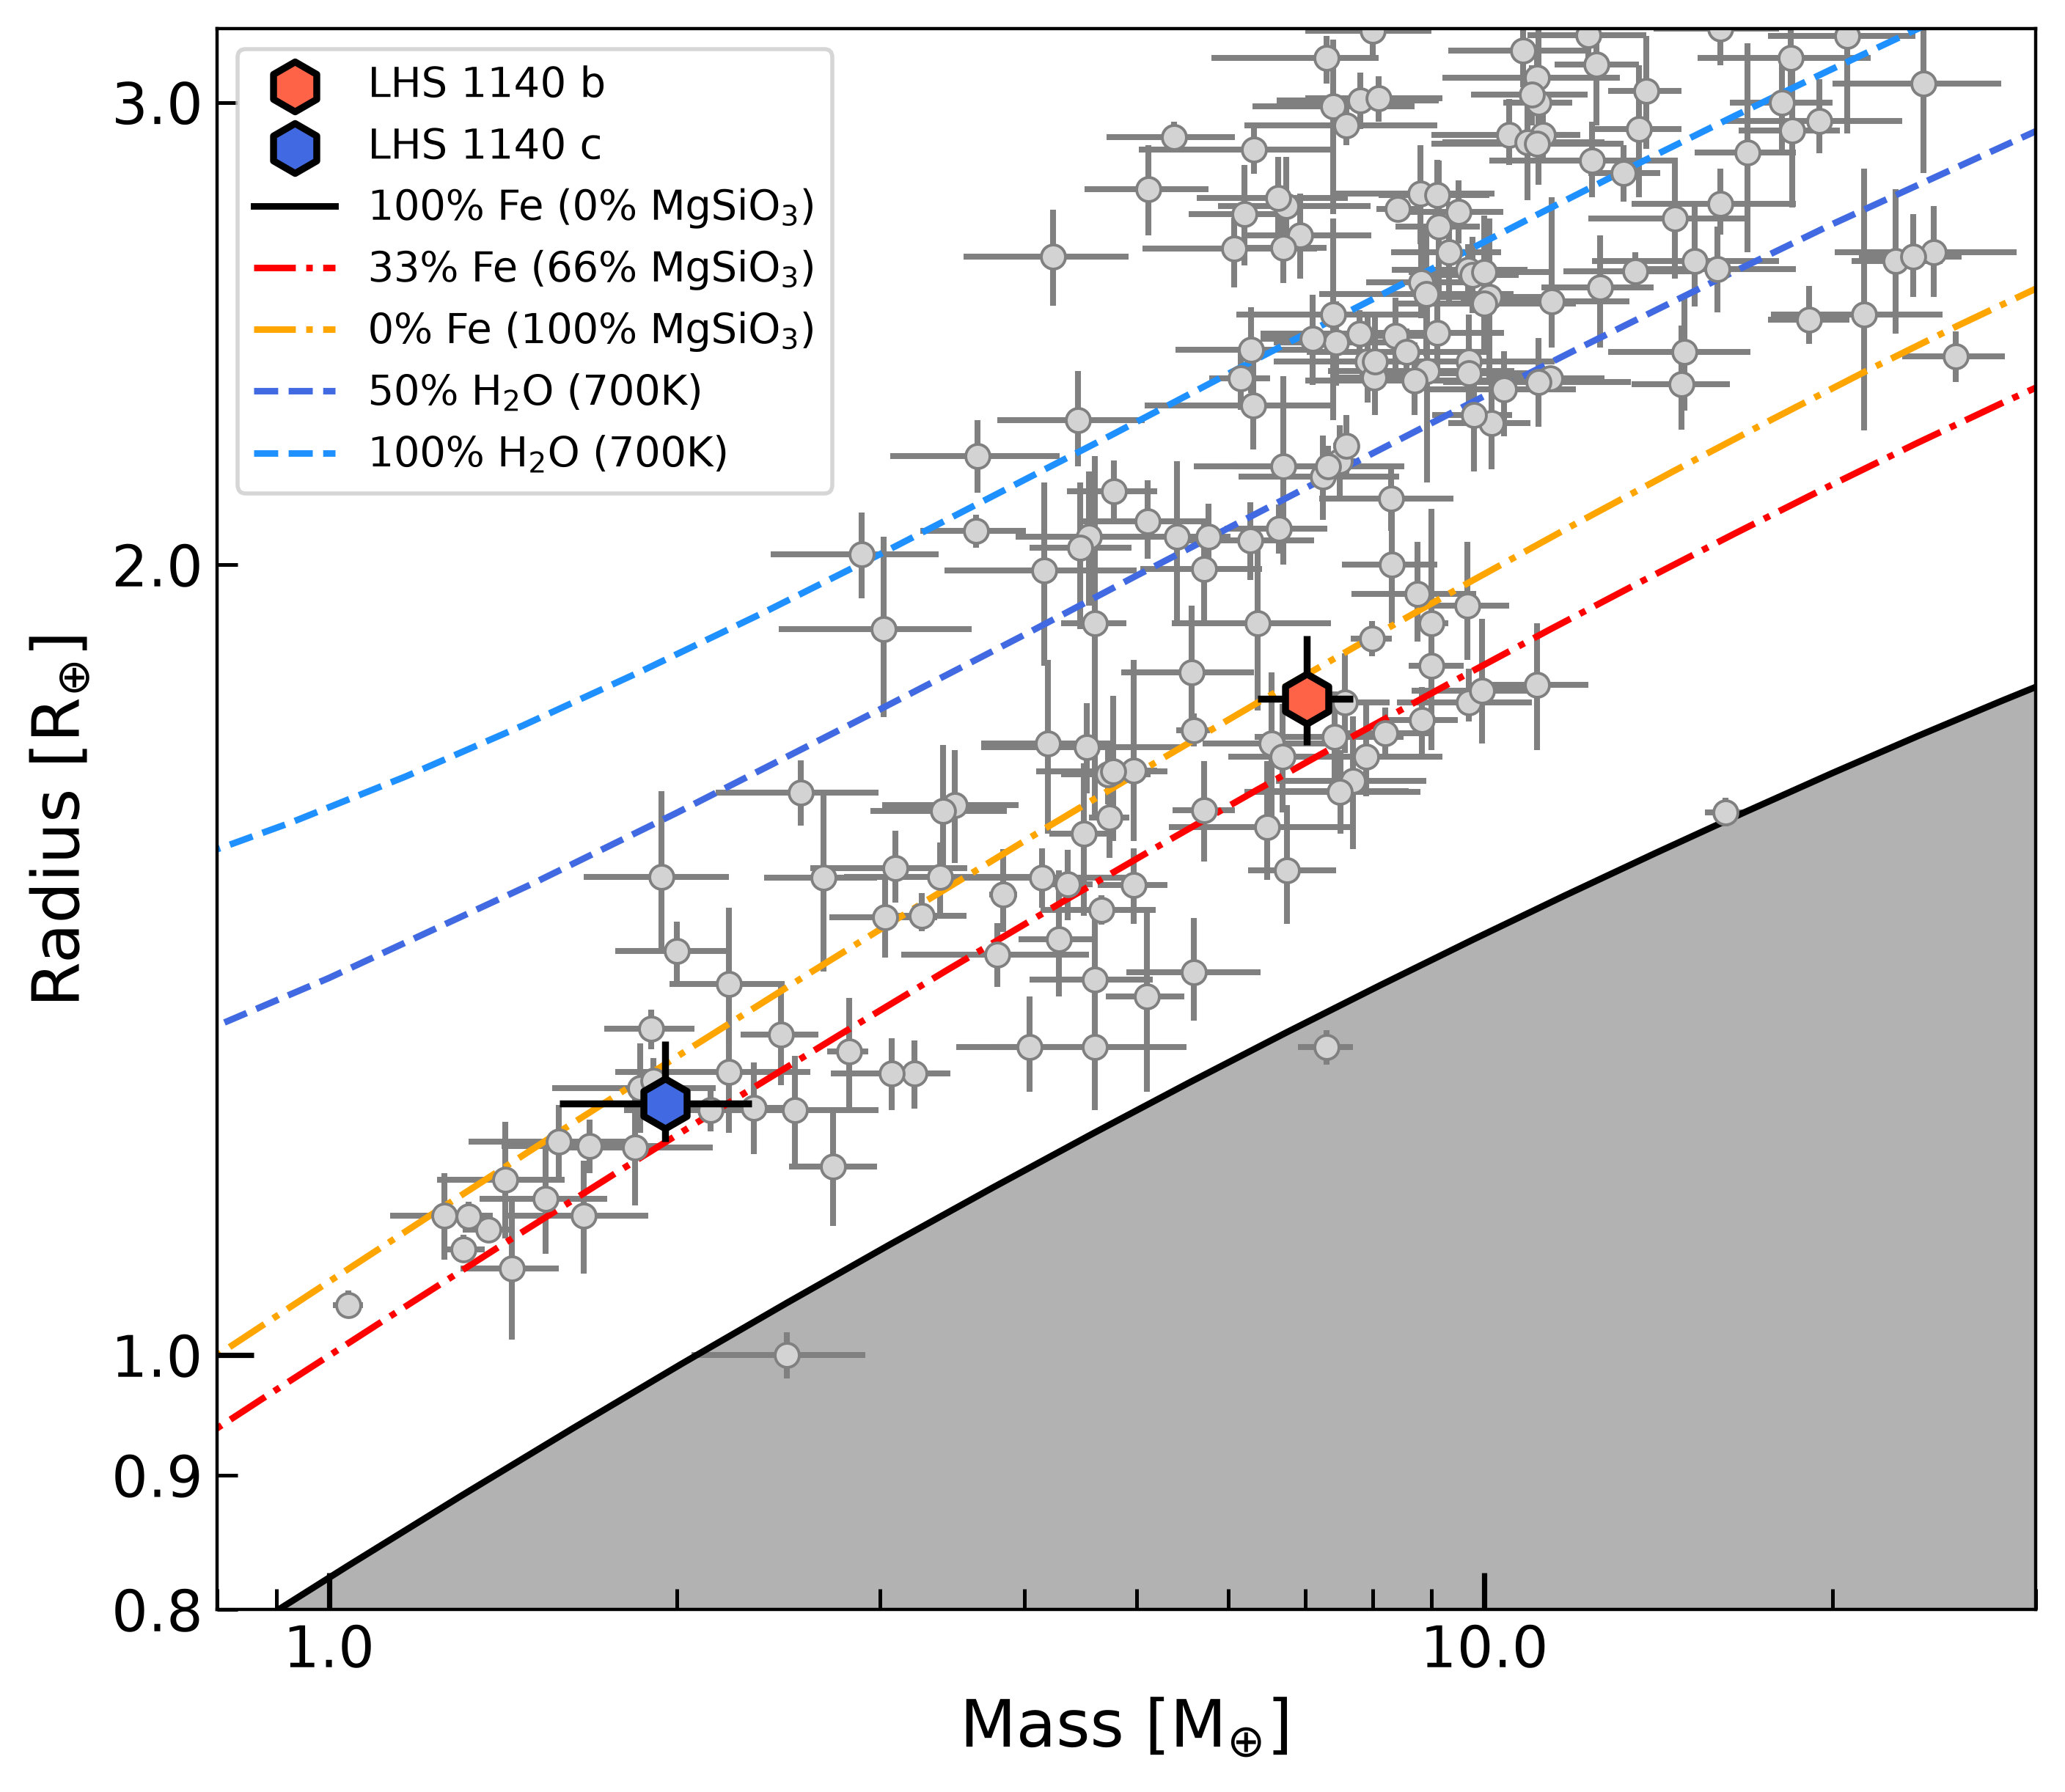

In [ ]:
Image("mr-plotter/output/lhs1140.png", width=650)

### Lectura del diagrama

Con la masa y el radio de este notebook (b: unos 7 M_earth y 1.78 R_earth), b cae sobre la curva de roca pura (100 % de MgSiO3) y muy por debajo de las de agua, y c cae entre la curva tipo Tierra y la de roca. Con las barras de error, los dos son compatibles con una composicion rocosa. Esto es distinto de lo que concluyen Cadieux et al. (2024) para b (minineptuno o mundo de agua), porque su masa es menor (5.60 M_earth) y su radio es parecido: la interpretacion depende de la masa, que es justo donde este trabajo difiere de la literatura (ver el notebook de RV).

Las curvas de Zeng et al. (2019) son de composicion fija y no incluyen una atmosfera ni una envoltura de gas, asi que no distinguen entre una roca y un planeta con una capa delgada de gas o de agua. mr-plotter tambien trae modelos de envolturas de agua (Turbet et al. 2020; Aguichine et al. 2021, 2025) que se pueden agregar en **[MODELS]**.

## Efecto fotoexcentrico

Ajuste con excentricidad y omega libres y con prior de densidad estelar, para ver si cambia el resultado del circular. Usa 40 caminantes y 12000 pasos (burn-in 3000), asi que su convergencia es menor que la del ajuste circular (ver resultados).

In [ ]:
# efecto fotoexcentrico: ajuste con e y omega libres + prior de densidad estelar
# parametros: [k, T0, P, b, sqrt(e)cos(w), sqrt(e)sin(w), rho_star, ln(jitter)]
# a/R* no es libre: sale de rho_star y P (tercera ley de Kepler). El resto del flujo es el del ajuste circular.
RHO_SUN = 1.410 # g/cm^3, densidad media del sol
RHO_STAR = RHO_SUN * MSTAR_MSUN / RSTAR_RSUN**3 # densidad de la estrella (g/cm^3)
RHO_ERR = RHO_STAR * np.hypot(MSTAR_ERR_MSUN / MSTAR_MSUN, 3 * RSTAR_ERR_RSUN / RSTAR_RSUN)
E_MAX = 0.5 # prior: e uniforme en [0, E_MAX]
G_CGS = 6.6743e-8 # G en cgs (codata 2018)
print(f"rho_star = {RHO_STAR:.1f} +- {RHO_ERR:.1f} g/cm^3")

# caminantes, pasos, burn-in y thin del ajuste excentrico, valores elegidos en este trabajo
NW_E = 40
NSTEPS_E = 12000
BURNIN_E = 3000
THIN_E = 10
ECC_NAMES = ["k", "T0", "P", "b", "sqrt(e)cos(w)", "sqrt(e)sin(w)", "rho_star", "ln(jitter)"]

rho_star = 25.8 +- 1.2 g/cm^3


### Semieje desde la densidad estelar
En el ajuste excentrico a/R* no es libre: se calcula con la densidad de la estrella y el periodo (tercera ley de Kepler)

In [ ]:
def a_rs_desde_rho(rho, period_days):
    # a/R* = (G rho P^2 / (3 pi))^(1/3)   (cgs)
    return (G_CGS * rho * (period_days * 86400.0)**2 / (3.0 * np.pi))**(1.0 / 3.0)

### Modelo de transito con e y omega
Se evalua el modelo de PyTransit con la excentricidad y el argumento del periastro. La inclinacion sale de b, e, omega y a/R*

In [ ]:
def evaluar_ecc(model, theta):
    k, t0, period, b, sq_c, sq_s, rho, log_jit = theta
    e = sq_c**2 + sq_s**2
    w = np.arctan2(sq_s, sq_c)
    a_rs = a_rs_desde_rho(rho, period)
    cos_i = b * (1.0 + e * np.sin(w)) / (a_rs * (1.0 - e**2))
    inc = np.arccos(np.clip(cos_i, -1.0, 1.0))
    return model.evaluate(k=k, ldc=LD_COEFF, t0=t0, p=period, a=a_rs, i=inc, e=e, w=w)

### Log-probabilidad con e libre
Priors uniformes, limite de e, y prior gaussiano para la densidad estelar, mas la verosimilitud gaussiana con jitter

In [ ]:
def log_prob_ecc(theta, t0_ref, p_ref, model, f, ferr):
    k, t0, period, b, sq_c, sq_s, rho, log_jit = theta
    # limites de los priors uniformes, elegidos en este trabajo
    e = sq_c**2 + sq_s**2
    if not (0.003 < k < 0.12):
        return -np.inf
    if not (abs(t0 - t0_ref) < 0.10):
        return -np.inf
    if not (abs(period - p_ref) < 0.005 * p_ref):
        return -np.inf
    if not (0.0 <= b < 1.0 + k):
        return -np.inf
    if not (e < E_MAX):
        return -np.inf
    if not (5.0 < rho < 80.0):
        return -np.inf
    if not (1e-7 < np.exp(log_jit) < 0.02):
        return -np.inf
    w = np.arctan2(sq_s, sq_c)
    a_rs = a_rs_desde_rho(rho, period)
    if b * (1.0 + e * np.sin(w)) / (a_rs * (1.0 - e**2)) >= 1.0:
        return -np.inf
    modelo = evaluar_ecc(model, theta)
    if not np.all(np.isfinite(modelo)):
        return -np.inf
    var = ferr**2 + np.exp(log_jit)**2
    loglike = -0.5 * np.sum((f - modelo)**2 / var + np.log(2.0 * np.pi * var))
    lp_rho = -0.5 * ((rho - RHO_STAR) / RHO_ERR)**2 # prior gaussiano de densidad estelar
    return loglike + lp_rho

### Funcion del ajuste con e libre
Mismo procedimiento que el ajuste circular, con los parametros de e y omega y la densidad estelar

In [ ]:
def ajustar_ecc(planet, seed=7):
    t_fit, f_fit, err_fit, t0_ref = select_planet_data(planet)
    p_ref = bls_results[planet]["period"]
    tm = make_transit_model(t_fit)
    centro = np.array([catalog[planet]["k"], t0_ref, p_ref, catalog[planet]["b_impact"],
                       0.05, 0.05, RHO_STAR, np.log(3e-4)])
    escala = np.array([max(catalog[planet]["k"] * 0.03, 2e-4), 0.001, p_ref * 1e-5, 0.05,
                       0.08, 0.08, 0.5 * RHO_ERR, 0.25])
    rng = np.random.default_rng(seed)
    pos = centro + escala * rng.normal(size=(NW_E, len(centro)))
    for j in range(NW_E):
        intentos = 0
        while not np.isfinite(log_prob_ecc(pos[j], t0_ref, p_ref, tm, f_fit, err_fit)):
            pos[j] = centro + escala * rng.normal(size=len(centro))
            intentos += 1
            if intentos > 10000:
                raise RuntimeError("No se pudo inicializar a los caminantes")
    sampler = emcee.EnsembleSampler(NW_E, len(centro), log_prob_ecc, args=(t0_ref, p_ref, tm, f_fit, err_fit))
    sampler.run_mcmc(pos, NSTEPS_E, progress=True)
    samples = sampler.get_chain(discard=BURNIN_E, thin=THIN_E, flat=True)
    return {"sampler": sampler, "samples": samples}

### Ejecutar el ajuste con e libre
Se corre para b y c. Tarda unos minutos por planeta

In [ ]:
fits_ecc = {}
for planet in fit_names:
    print(f"LHS 1140 {planet}: ajuste con e y omega libres")
    fits_ecc[planet] = ajustar_ecc(planet)

LHS 1140 b: ajuste con e y omega libres


100%|██████████| 12000/12000 [00:38<00:00, 312.78it/s]


LHS 1140 c: ajuste con e y omega libres


100%|██████████| 12000/12000 [01:00<00:00, 199.99it/s]


### Resultados del ajuste con e libre
Mediana de e y su limite superior al 95 %, densidad estelar posterior, radio con e libre y convergencia, comparados con la literatura (Cadieux et al. 2024)


LHS 1140 b:
  e = 0.151 +0.195 -0.119 | limite superior 95% = 0.442 (literatura: < 0.043)
  rho_star posterior = 25.8 +- 1.2 g/cm^3 (prior 25.8 +- 1.2)
  Rp = 1.743 R_earth (con e libre)
  aceptacion = 0.32 | pasos/tau_max = 44 (>50 es lo ideal)

LHS 1140 c:
  e = 0.113 +0.207 -0.089 | limite superior 95% = 0.435 (literatura: < 0.05)
  rho_star posterior = 25.7 +- 1.2 g/cm^3 (prior 25.8 +- 1.2)
  Rp = 1.236 R_earth (con e libre)
  aceptacion = 0.33 | pasos/tau_max = 52 (>50 es lo ideal)


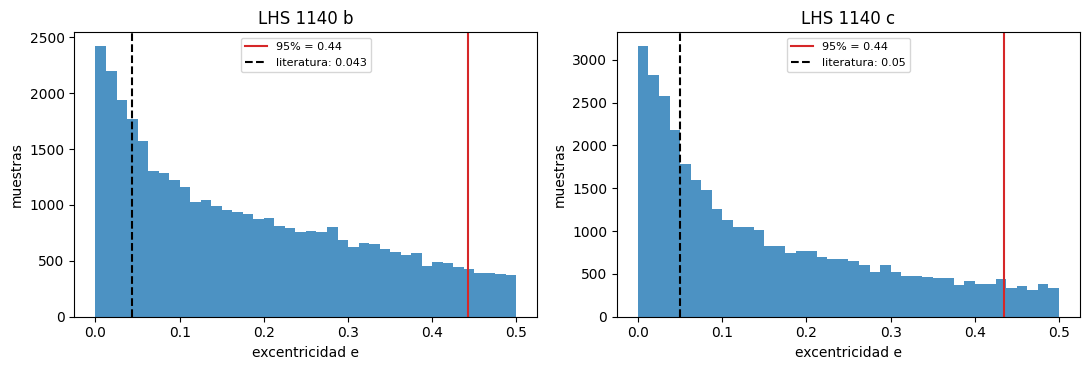

In [ ]:
# Claude Sonnet 5.5 (Anthropic): codigo de la figura
LIT_E95 = {"b": 0.043, "c": 0.050} # cadieux et al. (2024), Tabla D1, limites al 95%
fig, ax = plt.subplots(1, len(fit_names), figsize=(5.5 * len(fit_names), 3.8), squeeze=False)
for a, planet in zip(ax[0], fit_names):
    sampler = fits_ecc[planet]["sampler"]
    s = fits_ecc[planet]["samples"]
    e = s[:, 4]**2 + s[:, 5]**2
    p16, p50, p84, p95 = np.percentile(e, [16, 50, 84, 95])
    tau = sampler.get_autocorr_time(tol=0)
    print(f"\nLHS 1140 {planet}:")
    print(f"  e = {p50:.3f} +{p84 - p50:.3f} -{p50 - p16:.3f} | limite superior 95% = {p95:.3f} (literatura: < {LIT_E95[planet]})")
    print(f"  rho_star posterior = {np.median(s[:, 6]):.1f} +- {np.std(s[:, 6]):.1f} g/cm^3 (prior {RHO_STAR:.1f} +- {RHO_ERR:.1f})")
    rp = np.median(s[:, 0]) * RSTAR_RSUN * RSUN_TO_REARTH
    print(f"  Rp = {rp:.3f} R_earth (con e libre)")
    print(f"  aceptacion = {np.mean(sampler.acceptance_fraction):.2f} | pasos/tau_max = {sampler.iteration / np.max(tau):.0f} (>50 es lo ideal)")
    a.hist(e, bins=40, color="C0", alpha=0.8)
    a.axvline(p95, color="C3", ls="-", label=f"95% = {p95:.2f}")
    a.axvline(LIT_E95[planet], color="k", ls="--", label=f"literatura: {LIT_E95[planet]}")
    a.set_xlabel("excentricidad e")
    a.set_ylabel("muestras")
    a.set_title(f"LHS 1140 {planet}")
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Sistema visto desde arriba y zona habitable

Orbitas circulares de b y c y zona habitable, con los radios y masas de las secciones anteriores. Requiere haber corrido antes las secciones de radios, masas y semieje.

In [ ]:
# sistema LHS 1140 visto desde arriba: orbitas circulares + zona habitable
# requiere haber corrido antes las celdas de radios, masas y semieje (physical_results, mass_results, G, MSUN, DAY, AU).

# TEFF_STAR (K) viene del bloque de constantes (Cadieux et al. 2024, Tabla C1)
L_STAR = RSTAR_RSUN**2 * (TEFF_STAR / 5772.0)**4 # L/L_sun a partir de R y Teff (Teff del sol = 5772 K, iau 2015)

### Coeficientes de la zona habitable
Coeficientes de Kopparapu et al. (2013), Tabla 3, para los bordes de la zona habitable de una estrella. La estrella usa Teff = 3096 K (Cadieux et al. 2024, Tabla C1).

In [ ]:
KOP = { # kopparapu et al. (2013), Tabla 3 (valida para 2600 K <= Teff <= 7200 K): Seff_sun, a, b, c, d
    "Recent Venus": (1.7753, 1.4316e-4, 2.9875e-9, -7.5702e-12, -1.1635e-15),
    "Moist Greenhouse": (1.0140, 8.1774e-5, 1.7063e-9, -4.3241e-12, -6.6462e-16),
    "Maximum Greenhouse": (0.3438, 5.8942e-5, 1.6558e-9, -3.0045e-12, -5.2983e-16),
    "Early Mars": (0.3179, 5.4513e-5, 1.5313e-9, -2.7786e-12, -4.8997e-16),
}

### Bordes de la zona habitable
Funcion que calcula el borde (en ua) a partir de la temperatura efectiva y la luminosidad

In [ ]:
def borde_hz(nombre, teff, lum):
    s0, a, b, c, d = KOP[nombre]
    T = teff - 5780.0 # 5780 K: temperatura de referencia de Kopparapu et al. (2013)
    seff = s0 + a * T + b * T**2 + c * T**3 + d * T**4
    return np.sqrt(lum / seff) # ua

### Zona habitable de LHS 1140
Bordes conservador y optimista de la zona habitable

In [ ]:
hz_in_opt = borde_hz("Recent Venus", TEFF_STAR, L_STAR)
hz_in_con = borde_hz("Moist Greenhouse", TEFF_STAR, L_STAR)
hz_out_con = borde_hz("Maximum Greenhouse", TEFF_STAR, L_STAR)
hz_out_opt = borde_hz("Early Mars", TEFF_STAR, L_STAR)
print(f"L = {L_STAR:.5f} L_sun | ZH conservadora: {hz_in_con:.4f} a {hz_out_con:.4f} ua | optimista: {hz_in_opt:.4f} a {hz_out_opt:.4f} ua")

L = 0.00386 L_sun | ZH conservadora: 0.0671 a 0.1301 ua | optimista: 0.0507 a 0.1353 ua


### Datos de los planetas
Semieje, radio, masa e insolacion de cada planeta, tomados de las celdas anteriores

In [ ]:
# datos de cada planeta (ya calculados en el notebook)
datos = {}
for planet in fit_names:
    P = np.median(fits[planet]["samples"][:, 2]) * DAY
    a_au = (G * MSTAR_MSUN * MSUN * P**2 / (4 * np.pi**2))**(1/3) / AU
    datos[planet] = dict(a=a_au,
                         rp=physical_results.loc[planet, "Rp median (R_earth)"],
                         mp=mass_results[planet]["p50"],
                         S=L_STAR / a_au**2)

### Grafica del sistema
Sistema visto desde arriba: orbitas circulares y zona habitable. La posicion de cada planeta en su orbita es solo para dibujar

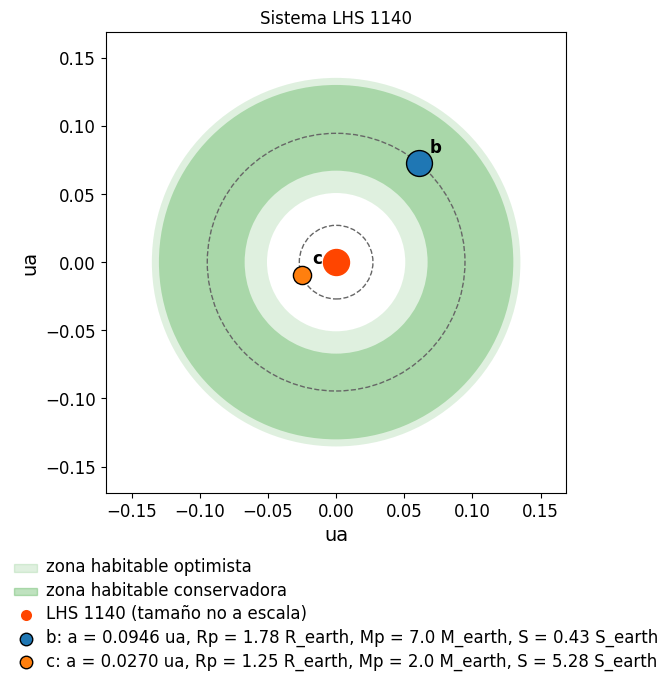

In [ ]:
# Claude Sonnet 5.5 (Anthropic): codigo de la figura
ANGULO = {"b": 50.0, "c": 200.0} # grados: posicion en la orbita, solo para dibujar
LIM = hz_out_opt * 1.25

fig, ax = plt.subplots(figsize=(6.5, 7.5))
ax.add_patch(Wedge((0, 0), hz_out_opt, 0, 360, width=hz_out_opt - hz_in_opt, color="tab:green", alpha=0.15, lw=0))
ax.add_patch(Wedge((0, 0), hz_out_con, 0, 360, width=hz_out_con - hz_in_con, color="tab:green", alpha=0.30, lw=0))
ax.scatter([0], [0], s=350, color="orangered", zorder=4)

handles = [Patch(color="tab:green", alpha=0.15, label="zona habitable optimista"),
           Patch(color="tab:green", alpha=0.30, label="zona habitable conservadora"),
           Line2D([0], [0], marker="o", color="w", markerfacecolor="orangered", markersize=9,
                  label="LHS 1140 (tamaño no a escala)")]
for color, (planet, d) in zip(["C0", "C1"], datos.items()):
    ax.add_patch(Circle((0, 0), d["a"], fill=False, ls="--", lw=1, color="0.4", zorder=2)) # orbita circular
    ang = np.radians(ANGULO[planet])
    x, y = d["a"] * np.cos(ang), d["a"] * np.sin(ang)
    ax.scatter([x], [y], s=110 * d["rp"]**2, color=color, edgecolor="k", zorder=5)
    ax.annotate(planet, (x, y), xytext=(8, 8), textcoords="offset points", fontsize=12, weight="bold")
    a_pl = d["a"]
    rp_pl = d["rp"]
    mp_pl = d["mp"]
    s_pl = d["S"]
    handles.append(Line2D([0], [0], marker="o", color="w", markerfacecolor=color, markeredgecolor="k", markersize=9,
                          label=f"{planet}: a = {a_pl:.4f} ua, Rp = {rp_pl:.2f} R_earth, Mp = {mp_pl:.1f} M_earth, S = {s_pl:.2f} S_earth"))

ax.set_xlim(-LIM, LIM)
ax.set_ylim(-LIM, LIM)
ax.set_aspect("equal")
ax.set_xlabel("ua")
ax.set_ylabel("ua")
ax.set_title("Sistema LHS 1140")
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8, frameon=False)
letra_grande(fig)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "sistema_LHS1140_orbitas.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusiones y limitaciones

Este notebook caracteriza los transitos de LHS 1140 b y c con fotometria de TESS. BLS refina el periodo; PyTransit modela la forma del transito; MCMC estima las distribuciones posteriores de $R_p/R_\star$, $T_0$, $P$, $a/R_\star$, $b$ y el ruido adicional. Cada radio se combina con la masa de las velocidades radiales para obtener la densidad.

### Limitaciones

- **Pocos transitos en b:** con P = 24.7 d, el ajuste de b descansa en 3 transitos completos; c tiene 17 (13 completos y 4 parciales, con el criterio de mayor o igual que 65 puntos), ver la seccion Conteo de transitos de b y c.
- **Limb darkening:** fijado con los coeficientes de TESS de Cadieux et al. (2024); lo ideal seria ajustarlos con priors.
- **Aplanado:** **flatten(window_length=901)** con los transitos enmascarados; repetir con otras ventanas y comprobar estabilidad.
- **Ajuste independiente:** cada planeta se ajusta por separado y se enmascaran los transitos del otro. El siguiente nivel es un ajuste simultaneo.
- **Orbita circular:** la relacion entre $b$ e inclinacion supone excentricidad cero. El ajuste con e libre (seccion Efecto fotoexcentrico) da limites al 95 % de 0.45 (b) y 0.44 (c): TESS solo no restringe la excentricidad.
- **Ruido correlacionado:** **jitter** es ruido blanco adicional; no sustituye un proceso gaussiano.
- **Convergencia:** ajuste circular con 32 caminantes, burn-in de 8000 y 25000 pasos (12000 + 13000). Con esos pasos, b da 60 veces tau y c 35, que no cumple el criterio de 50, asi que se alargaron las cadenas de c (ver la celda de Steps / max(tau) despues de la ampliacion). El ajuste con e libre (40 caminantes, 12000 pasos) da menos de 50 veces tau, asi que sus resultados son orientativos.
- **Linea base larga:** los sectores 3, 30 y 107 abarcan de 2018 a 2026, asi que el periodo y T0 quedan muy correlacionados, sobre todo en c. Revisar trazas y autocorrelacion, y si las cadenas divagan, acotar el prior del periodo con el valor publicado.
- **Radio estelar:** se usa el valor publicado con su incertidumbre propagada.
- **Masa de b:** sale 2.0sigma por encima de la literatura (7.02 frente a 5.60 M_earth) porque el K de HARPS con LBL (cerca de 4.8 m/s) es mayor que el publicado (3.80 m/s); el analisis de RV muestra un exceso de señal cerca de la rotacion de la estrella (134 d). Ajustar esa señal junto con b y c (notebook de RV) da K_b = 4.71 +- 0.40 m/s, asi que no explica la diferencia.

### Referencias

- Cadieux et al. (2024), **New Mass and Radius Constraints on the LHS 1140 Planets: LHS 1140 b Is Either a Temperate Mini-Neptune or a Water World**, arXiv:2310.15490.
- Kipping, D. M. (2013), **Efficient, uninformative sampling of limb darkening coefficients for two-parameter laws**, MNRAS, 435, 2152.
- Mandel, K. & Agol, E. (2002), **Analytic Light Curves for Planetary Transit Searches**, ApJ, 580, L171. https://doi.org/10.1086/345520
- Parviainen, H. (2015), **PyTransit: fast and easy exoplanet transit modelling in Python**, MNRAS, 450, 3233. https://doi.org/10.1093/mnras/stv894
- Foreman-Mackey et al. (2013), **emcee: The MCMC Hammer**, PASP, 125, 306. https://doi.org/10.1086/670067
- Kopparapu, R. K. et al. (2013), **Habitable Zones around Main-sequence Stars: New Estimates**, ApJ, 765, 131.
- Lightkurve Collaboration (2018), **Lightkurve: Kepler and TESS time series analysis in Python**, Astrophysics Source Code Library, ascl:1812.013.
- Ricker, G. R. et al. (2015), **Transiting Exoplanet Survey Satellite (TESS)**, JATIS, 1, 014003.
- Jenkins, J. M. et al. (2016), **The TESS science processing operations center**, Proc. SPIE, 9913, 99133E.
- Astropy Collaboration (2022), **The Astropy Project: Sustaining and Growing a Community-oriented Open-source Project and the Latest Major Release (v5.0) of the Core Package**, ApJ, 935, 167.
- Datos: curvas de luz de TESS del archivo MAST (https://archive.stsci.edu).

**Fin del notebook.**
- Castro-Gonzalez, A., **mr-plotter**, https://github.com/castro-gzlz/mr-plotter. Catalogo: NASA Exoplanet Archive (Christiansen et al. 2025, PSJ, 6, 186).
- Zeng, L. et al. (2019), **Growth model interpretation of planet size distribution**, PNAS, 116, 9723.

Agradecimiento (lo pide el autor de mr-plotter): This work made use of mr-plotter (available at https://github.com/castro-gzlz/mr-plotter).
